In [1]:
# Automatically reload the package if you edit the .py files
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings("ignore") # remove scanpy warnings for the tutorial.
# Import the new package name
import decipher as dc

ModuleNotFoundError: No module named 'decipher'

In [ ]:
dc.pl.activate_journal_quality()

# Load data

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc 

In [ ]:
import matplotlib
print(matplotlib.__version__)
import IPython
print(IPython.__version__)

3.10.8
9.12.0


In [ ]:
import os
print(os.getcwd())

/Users/jihyunpark/Documents/Columbia/2026 Spring/Decipher Project/decipher-bc-condition-z-to-x/examples


In [ ]:
color_palette = None
path = '/Users/jihyunpark/Documents/Columbia/2026 Spring/Decipher Project/xenium_exploration/20260207_adata_preprocessed_full.h5ad'
adata = sc.read_h5ad(path)
adata.uns["color_palette"] = None

In [ ]:
color_palette = None
adata = sc.read_h5ad('adata_categories_edited.h5ad')
adata.uns["color_palette"] = None

 delete batch
 subset by tumor

In [ ]:
print(adata.obs.columns)

Index(['centroid_x', 'centroid_y', 'centroid_z', 'fov', 'cluster', 'volume',
       'population', 'cell_num', 'Unnamed: 0', 'sample_num', 'sample_id',
       'sample_type', 'TMA', 'batch', 'log10_total_counts', 'leiden',
       'density_status', 'atypical', 'deviation_score', 'log_lib_size',
       'cell_type', 'TMA_ID', 'OS_days',
       'survival sample date to death (days)', 'treatment', 'biopsy_site',
       'biopsy_site_classification', 'sample_site',
       'primary site classification', 'age_(yrs)', 'sex', 'PDL1 (TPS%)',
       'PDL1', 'NUT-fusion', 'note:', 'Registry participant? (YES/n)',
       'NC registry ID', 'accession no.', 'treatment_status', 'OS_cat',
       'sample_name', 'ex_group', 'cell_type_L2', 'cell_type_L1',
       'cell_type_L0', 'cell_type_general', 'cell_type_L3', 'cell_id'],
      dtype='object')


In [ ]:
del adata.obs['batch']

In [ ]:
print(adata.layers)

Layers with keys: counts, log_counts


* Note: adata.X has log_counts

In [ ]:
adata_temp = adata.copy()
import scanpy as sc

# 1. Create a new layer by copying the raw counts
adata_temp.layers['norm_log_counts'] = adata_temp.layers['counts'].copy()

# 2. Normalize the specific layer (standard is 10,000 counts per cell)
sc.pp.normalize_total(adata_temp, target_sum=1e4, layer='norm_log_counts')

# 3. Log-transform the specific layer
sc.pp.log1p(adata_temp, layer='norm_log_counts')


In [ ]:
# 1. Create a new layer by copying the raw counts
adata_temp.layers['my_log_counts'] = adata_temp.layers['counts'].copy()

# 2. Normalize the specific layer (standard is 10,000 counts per cell)
#sc.pp.normalize_total(adata_temp, target_sum=1e4, layer='my_log_counts')

# 3. Log-transform the specific layer
sc.pp.log1p(adata_temp, layer='my_log_counts')


In [ ]:
import pandas as pd
import scipy.sparse

def peek_matrix(data, name):
    # If it's a sparse matrix, convert a small slice to dense to view it
    if scipy.sparse.issparse(data):
        view = data[:5, :5].toarray()
    else:
        view = data[:5, :5]
    
    print(f"\n--- {name} ---")
    print(pd.DataFrame(view))

# Check the default matrix
peek_matrix(adata.X, "adata.X")

# Check the layers
if 'counts' in adata.layers:
    peek_matrix(adata.layers['counts'], "Layer: counts")

if 'log_counts' in adata.layers:
    peek_matrix(adata.layers['log_counts'], "Layer: log_counts")
    
if 'my_log_counts' in adata_temp.layers:
    peek_matrix(adata_temp.layers['my_log_counts'], "Layer: my_log_counts")
    
if 'norm_log_counts' in adata_temp.layers:
    peek_matrix(adata_temp.layers['norm_log_counts'], "Layer: norm_log_counts")


--- adata.X ---
          0         1    2         3    4
0  0.000000  2.509223  0.0  2.123568  0.0
1  0.175029  0.000000  0.0  0.295906  0.0
2  0.000000  0.000000  0.0  1.361277  0.0
3  0.020701  0.000000  0.0  1.155431  0.0
4  2.056070  0.000000  0.0  2.248315  0.0

--- Layer: counts ---
           0          1    2          3    4
0   0.000000  29.570568  0.0  19.270403  0.0
1   0.050001   0.000000  0.0   0.090011  0.0
2   0.000000   0.000000  0.0   3.690087  0.0
3   0.010000   0.000000  0.0   1.040020  0.0
4  18.500364   0.000000  0.0  22.997246  0.0

--- Layer: log_counts ---
          0         1    2         3    4
0  0.000000  2.509223  0.0  2.123568  0.0
1  0.175029  0.000000  0.0  0.295906  0.0
2  0.000000  0.000000  0.0  1.361277  0.0
3  0.020701  0.000000  0.0  1.155431  0.0
4  2.056070  0.000000  0.0  2.248315  0.0

--- Layer: my_log_counts ---
          0         1    2         3    4
0  0.000000  3.420038  0.0  3.009162  0.0
1  0.048791  0.000000  0.0  0.086188  0.0
2  

In [ ]:
adata_tumor = adata_temp[adata_temp.obs['sample_type'] == 'tumor', :].copy()


In [ ]:
adata_tumor.shape

(436005, 423)

In [ ]:
# 2. Sample 25,000 cells from every group in the 'batch' column
sampled_indices = (
    adata_tumor.obs.groupby('TMA')
    .sample(n=25000, random_state=42)
    .index
)

# 3. Slice the original AnnData object
adata_tumor_balanced = adata_tumor[sampled_indices].copy()

# Verification
print(adata_tumor_balanced.obs['TMA'].value_counts())

TMA
479    25000
480    25000
Name: count, dtype: int64


In [ ]:
adata_tumor_balanced.obs.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50000 entries, 444484 to 243816
Data columns (total 47 columns):
 #   Column                                Non-Null Count  Dtype   
---  ------                                --------------  -----   
 0   centroid_x                            50000 non-null  float64 
 1   centroid_y                            50000 non-null  float64 
 2   centroid_z                            50000 non-null  float64 
 3   fov                                   50000 non-null  category
 4   cluster                               50000 non-null  category
 5   volume                                50000 non-null  float64 
 6   population                            50000 non-null  int64   
 7   cell_num                              50000 non-null  category
 8   Unnamed: 0                            50000 non-null  int64   
 9   sample_num                            50000 non-null  float64 
 10  sample_id                             50000 non-null  category
 11  s

In [ ]:
# # Ensure we treat them as strings if they are categories
# adata_batch0 = adata[adata.obs['TMA_batch'].astype(str) == '0']
# adata_batch1 = adata[adata.obs['TMA_batch'].astype(str) == '1']

# # Safety Check: Print sizes to confirm they aren't empty
# print(f"Batch 0 size: {adata_batch0.n_obs}")
# print(f"Batch 1 size: {adata_batch1.n_obs}")

# batch0_subset = sc.pp.subsample(adata_batch0, n_obs=50000, random_state=42, copy=True)
# batch1_subset = sc.pp.subsample(adata_batch1, n_obs=50000, random_state=42, copy=True)

# print(batch0_subset.layers['counts'][:5, :5])

Batch 0 size: 292068
Batch 1 size: 403192


If the max is < 20: You are likely looking at Log-normalized data. Do not round. You need to find the actual raw counts layer.

If the max is > 100: You are likely looking at Corrected counts (like CellBender). Rounding is safe and necessary.

The 'counts' layer contained fractional values, likely due to ambient RNA correction or scaling. I rounded these to the nearest integer to satisfy the integer-count requirement of the Negative Binomial likelihood in our Decipher model.

Raw counts — do not log-normalize before running Decipher.
Decipher is a generative model built around a negative binomial likelihood, so it explicitly models count data. Internally, it learns normalized gene expression means via a softmax output layer and accounts for each cell's library size directly (the final observed counts are generated from a negative binomial with mean µᵢ,ᵍ · lᵢ, where lᵢ is the observed library size). The paper also explicitly states: "no other pre-processing or normalization was performed, as the model is always run on raw counts data."

In [ ]:
import scipy.sparse as sp

def round_counts(adata):
    counts = adata.layers['counts'].copy()
    if sp.issparse(counts):
        counts.data = counts.data.round().astype(int)
    else:
        counts = counts.round().astype(int)
    adata.X = counts
    return adata

# batch0_subset_dc = round_counts(batch0_subset)
# batch1_subset_dc = round_counts(batch1_subset)
adata_tumor_balanced_dc = round_counts(adata_tumor_balanced)

In [ ]:
adata_tumor_balanced_dc.write_h5ad("adata_tumor_balanced_dc.h5ad", compression="gzip")

# Train ex_group

In [ ]:
plt.rcParams['axes.titlesize'] = 15

In [ ]:
adata_tumor_balanced_dc1 = adata_tumor_balanced_dc.copy()

# Ensure the 'decipher' key exists in the metadata
if "decipher" not in adata_tumor_balanced_dc1.uns:
    adata_tumor_balanced_dc1.uns["decipher"] = {}
    
# Manually stamp the batch_key used during training (e.g., 'TMA_batch')
# This is the step that fixes the "No Batch Correction" title issue
adata_tumor_balanced_dc1.uns["decipher"]["config"] = {"batch_key": "TMA"}

## seed 1

Epoch 21 (batch 703/703) | | train elbo: 1577749440366.08 (last epoch: 161649761960.89) | val ll: 274.29:   2%|▏         | 21/1000 [21:45<16:54:01, 62.15s/it]2026-05-14 00:23:40,479 | INFO : Early stopping has been triggered.
2026-05-14 00:23:41,569 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-14 00:23:41,571 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-14 00:23:41,574 | INFO : Saving decipher model with run_id 2026-05-14-00-23-41-gourmet-crimson-free.


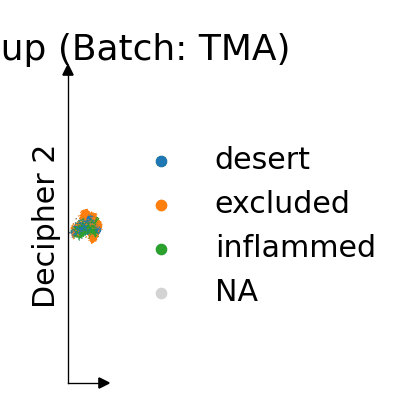

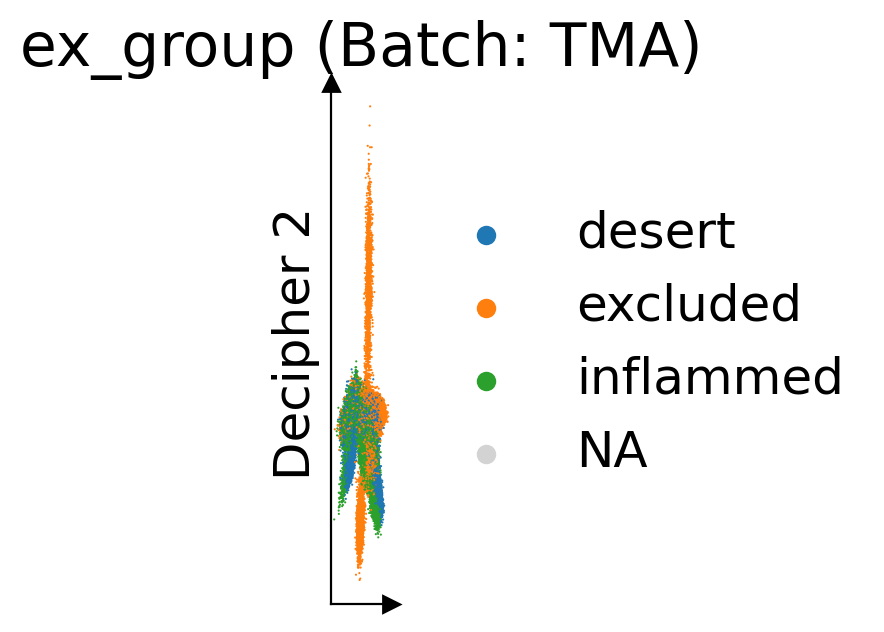

In [ ]:
# Lower learning rate
from decipher.tools._decipher import DecipherConfig
decipher_config = DecipherConfig(learning_rate=1e-3, seed = 1)

# Train Decipher
d1, val1 = dc.tl.decipher_train(
    adata_tumor_balanced_dc1, decipher_config, 
    plot_kwargs={"color": "ex_group"}, 
    batch_key="TMA",
    plot_every_k_epochs=5,
)

2026-05-13 23:54:59,171 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-13 23:54:59,173 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


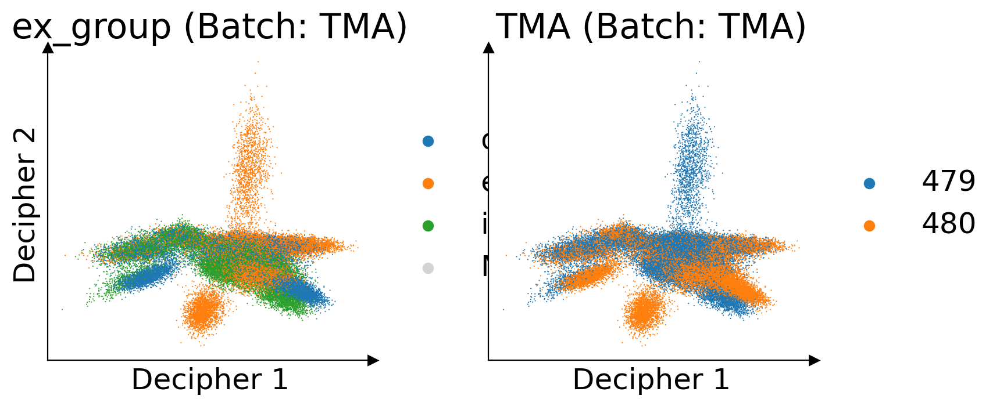

In [ ]:
dc.tl.decipher_rotate_space(
    adata_tumor_balanced_dc1,
    v1_col="ex_group",
    v1_order=["desert", "excluded", "inflammed", "NA"],
    v2_col="TMA",
    v2_order=["479", "480"],
)
# Decipher 1: ex_group, Decipher 2: TMA
dc.pl.decipher(adata_tumor_balanced_dc1, ["ex_group", "TMA"], palette=color_palette);

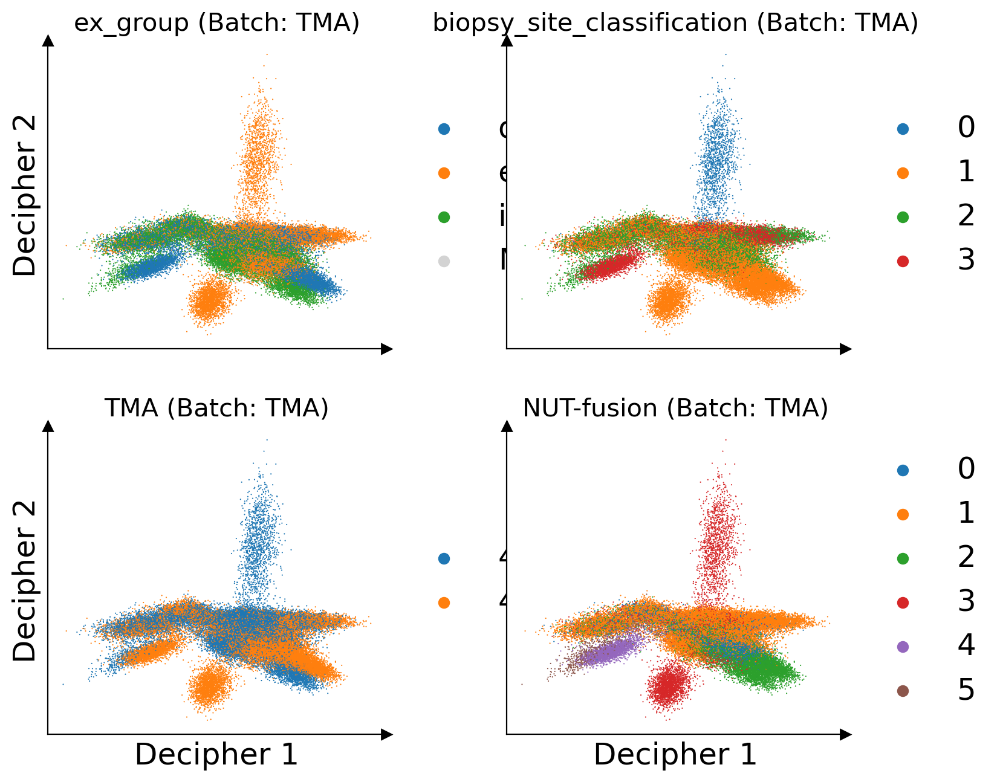

In [ ]:
plt.rcParams['axes.titlesize'] = 15
dc.pl.decipher(adata_tumor_balanced_dc1, ["ex_group", "biopsy_site_classification", "TMA", "NUT-fusion"], palette=color_palette);

In [ ]:
adata_tumor_balanced_dc1.obsm['decipher_v_seed1'] = adata_tumor_balanced_dc1.obsm['decipher_v'].copy()

## seed 2

Epoch 18 (batch 703/703) | | train elbo: 238.04 (last epoch: 238.15) | val ll: 250.59:   2%|▏         | 18/1000 [11:43<10:39:18, 39.06s/it]2026-05-08 00:08:04,103 | INFO : Early stopping has been triggered.
2026-05-08 00:08:04,624 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 00:08:04,625 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-08 00:08:04,628 | INFO : Saving decipher model with run_id 2026-05-08-00-08-04-parallel-angry-block.


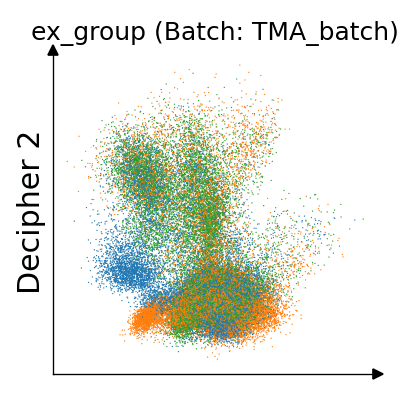

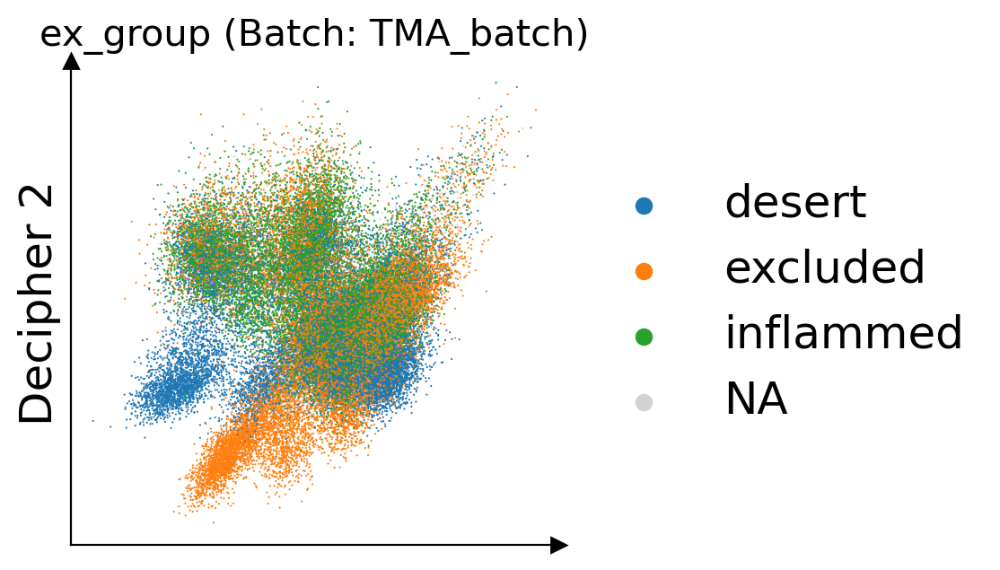

In [ ]:
decipher_config2 = DecipherConfig(learning_rate=1e-3, seed = 2)

# Train Decipher
d2, val2 = dc.tl.decipher_train(
    adata_balanced_dc1, decipher_config2, 
    plot_kwargs={"color": "ex_group"}, 
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

2026-05-08 00:10:50,667 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 00:10:50,668 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


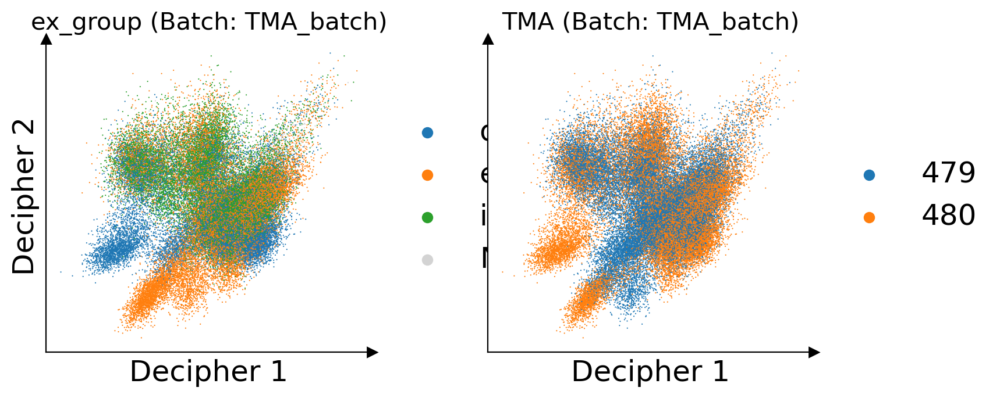

In [ ]:
dc.tl.decipher_rotate_space(
    adata_balanced_dc1,
    v1_col="ex_group",
    v1_order=["desert", "excluded", "inflammed", "NA"],
    v2_col="TMA",
    v2_order=["479", "480"],
)
# Decipher 1: ex_group, Decipher 2: TMA
dc.pl.decipher(adata_balanced_dc1, ["ex_group", "TMA"], palette=color_palette);

adata_balanced_dc1.obsm['decipher_v_seed2'] = adata_balanced_dc1.obsm['decipher_v'].copy()

# biopsy site

In [ ]:
adata_balanced_dc_biopsy = adata_balanced_dc.copy()

# Ensure the 'decipher' key exists in the metadata
if "decipher" not in adata_balanced_dc_biopsy.uns:
    adata_balanced_dc_biopsy.uns["decipher"] = {}
    
# Manually stamp the batch_key used during training (e.g., 'TMA_batch')
# This is the step that fixes the "No Batch Correction" title issue
adata_balanced_dc_biopsy.uns["decipher"]["config"] = {"batch_key": "TMA"}

## seed 1

Epoch 18 (batch 703/703) | | train elbo: 237.07 (last epoch: 237.32) | val ll: 251.27:   2%|▏         | 18/1000 [06:01<5:28:58, 20.10s/it]2026-05-08 13:53:14,511 | INFO : Early stopping has been triggered.
2026-05-08 13:53:15,019 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 13:53:15,019 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-08 13:53:15,020 | INFO : Saving decipher model with run_id 2026-05-08-13-53-15-nuclear-avocado-quantum.


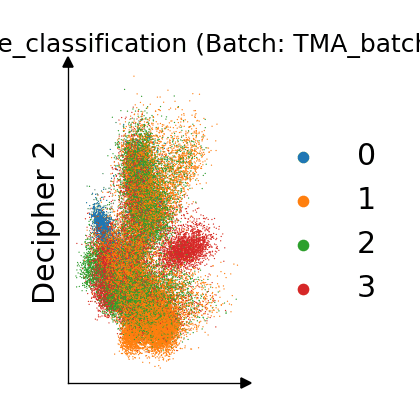

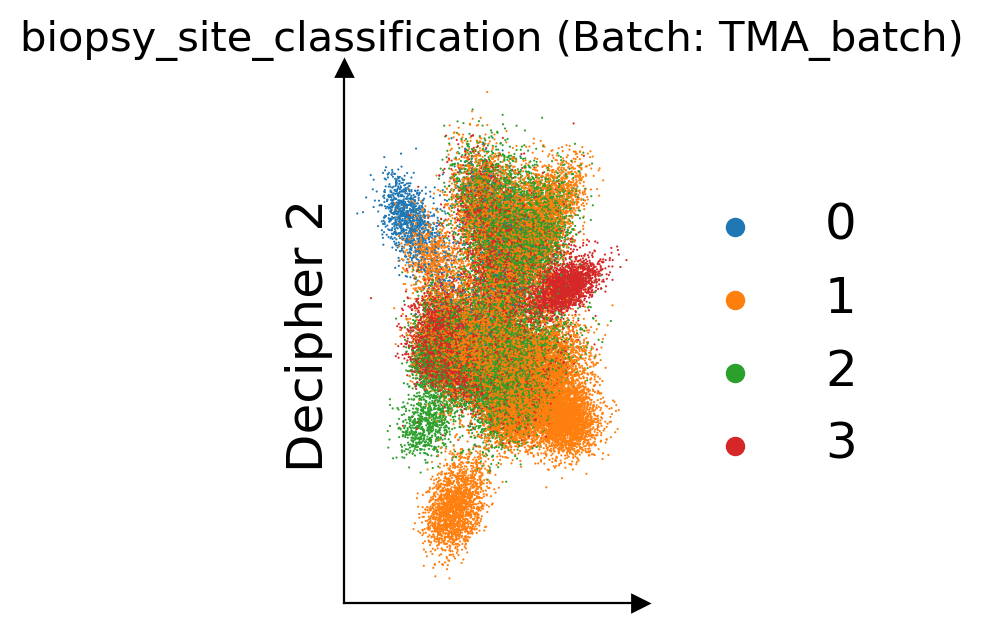

In [ ]:
biopsy_config1 = DecipherConfig(learning_rate=1e-3, seed = 1)

# Train Decipher
biopsy_d1, biopsy_v1 = dc.tl.decipher_train(
    adata_balanced_dc_biopsy, biopsy_config1, 
    plot_kwargs={"color": "biopsy_site_classification"}, 
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

adata_balanced_dc_biopsy.obsm['decipher_v_seed1'] = adata_balanced_dc_biopsy.obsm['decipher_v'].copy()

2026-05-08 13:58:23,048 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 13:58:23,050 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


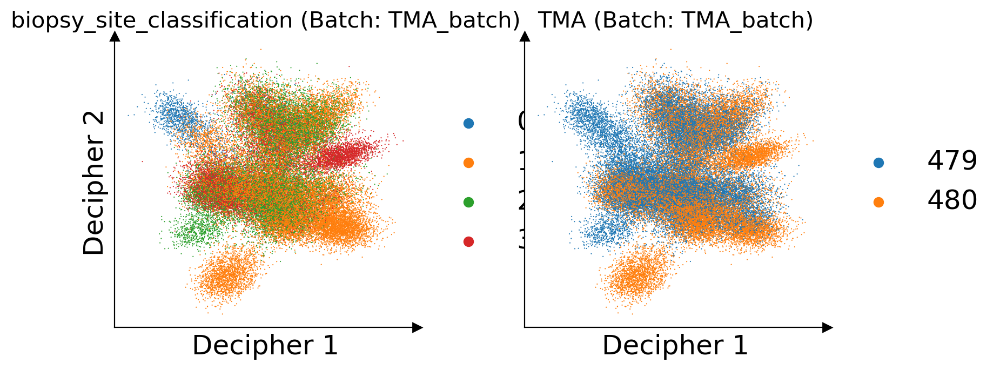

In [ ]:
dc.tl.decipher_rotate_space(
    adata_balanced_dc_biopsy,
    v1_col="biopsy_site_classification",
    v1_order=["0", "1", "2", "3"],
    v2_col="TMA",
    v2_order=["479", "480"],
)
# Decipher 1: biopsy_site_classification, Decipher 2: TMA
dc.pl.decipher(adata_balanced_dc_biopsy, ["biopsy_site_classification", "TMA"], palette=color_palette);

## seed 2

Epoch 18 (batch 703/703) | | train elbo: 238.04 (last epoch: 238.15) | val ll: 250.59:   2%|▏         | 18/1000 [11:05<10:05:15, 36.98s/it]2026-05-08 14:12:37,720 | INFO : Early stopping has been triggered.
2026-05-08 14:12:38,366 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 14:12:38,367 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-08 14:12:38,369 | INFO : Saving decipher model with run_id 2026-05-08-14-12-38-lower-ornery-toast.


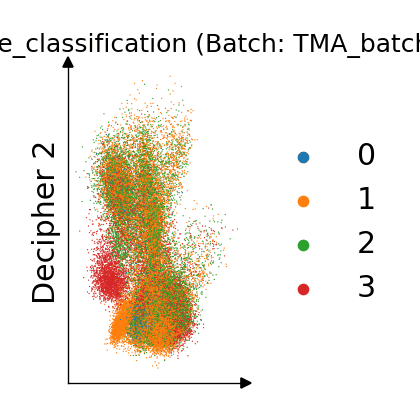

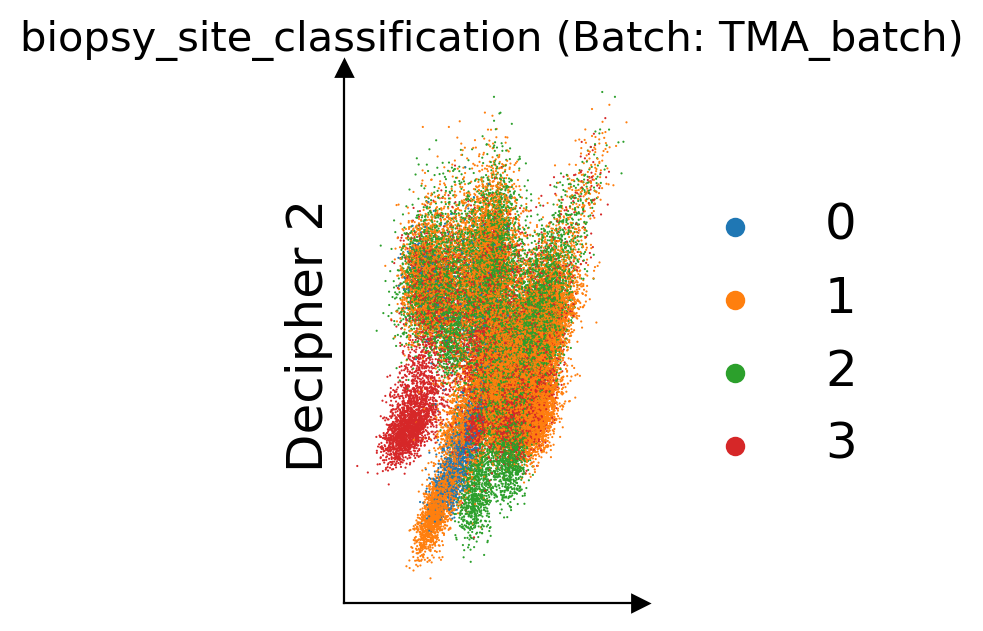

In [ ]:
biopsy_config2 = DecipherConfig(learning_rate=1e-3, seed = 2)

# Train Decipher
biopsy_d2, biopsy_v2 = dc.tl.decipher_train(
    adata_balanced_dc_biopsy, biopsy_config2, 
    plot_kwargs={"color": "biopsy_site_classification"}, 
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

adata_balanced_dc_biopsy.obsm['decipher_v_seed2'] = adata_balanced_dc_biopsy.obsm['decipher_v'].copy()

2026-05-08 14:13:28,002 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 14:13:28,004 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


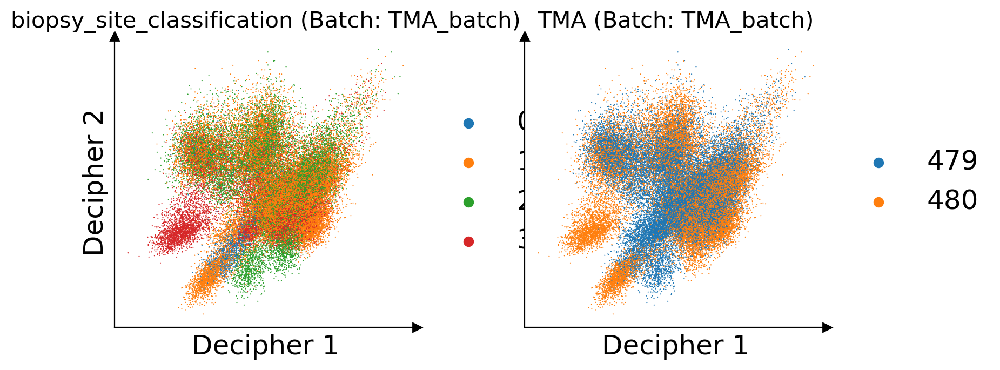

In [ ]:
dc.tl.decipher_rotate_space(
    adata_balanced_dc_biopsy,
    v1_col="biopsy_site_classification",
    v1_order=["0", "1", "2", "3"],
    v2_col="TMA",
    v2_order=["479", "480"],
)
# Decipher 1: biopsy_site_classification, Decipher 2: TMA
dc.pl.decipher(adata_balanced_dc_biopsy, ["biopsy_site_classification", "TMA"], palette=color_palette);

## gather seeds

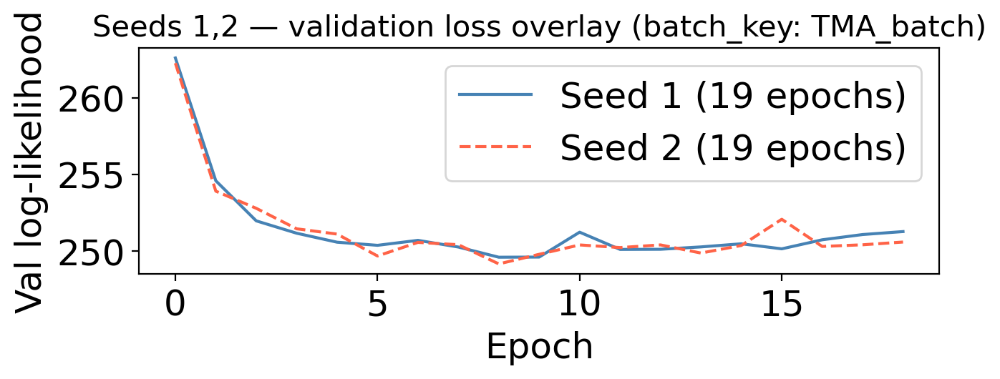

In [ ]:
run1 = adata_balanced_dc_biopsy.obsm['decipher_v_seed1']
run2 = adata_balanced_dc_biopsy.obsm['decipher_v_seed2']
#run3 = adata_balanced_dc_biopsy.obsm['decipher_v_seed3']

n_epochs_run1 = len(biopsy_v1)
n_epochs_run2 = len(biopsy_v2)
#n_epochs_run3 = len(biopsy_v3)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(biopsy_v1, color="steelblue", linewidth=1.5, label=f"Seed 1 ({n_epochs_run1} epochs)")
ax.plot(biopsy_v2, color="tomato",    linewidth=1.5, label=f"Seed 2 ({n_epochs_run2} epochs)",
        linestyle="--")
#ax.plot(biopsy_v3, color="green",   linewidth=1.5, label=f"Seed 3 ({n_epochs_run3} epochs)",
        #linestyle="-.")
ax.set_xlabel("Epoch")
ax.set_ylabel("Val log-likelihood")
ax.set_title("Seeds 1,2 — validation loss overlay (batch_key: TMA_batch)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
def myfunc(my_interest, batch_key):
    grouped = []
    grouped.append(my_interest)
    grouped.append(batch_key)
    print(grouped)
    
myfunc(my_interest="biopsy_site_classification", batch_key="TMA_batch")

['biopsy_site_classification', 'TMA_batch']


# Train: NUT-fusion

In [ ]:
plt.rcParams['axes.titlesize'] = 15

In [ ]:
adata_balanced_dc2 = adata_balanced_dc.copy()

# Ensure the 'decipher' key exists in the metadata
if "decipher" not in adata_balanced_dc2.uns:
    adata_balanced_dc2.uns["decipher"] = {}
    
# Manually stamp the batch_key used during training (e.g., 'TMA_batch')
# This is the step that fixes the "No Batch Correction" title issue
adata_balanced_dc2.uns["decipher"]["config"] = {"batch_key": "TMA"}

Epoch 39 (batch 703/703) | | train elbo: 237.00 (last epoch: 236.99) | val ll: 249.76:   4%|▍         | 39/1000 [13:42<5:37:39, 21.08s/it]2026-05-08 00:34:35,183 | INFO : Early stopping has been triggered.
2026-05-08 00:34:35,602 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 00:34:35,604 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-08 00:34:35,605 | INFO : Saving decipher model with run_id 2026-05-08-00-34-35-gravitational-khaki-fractal.


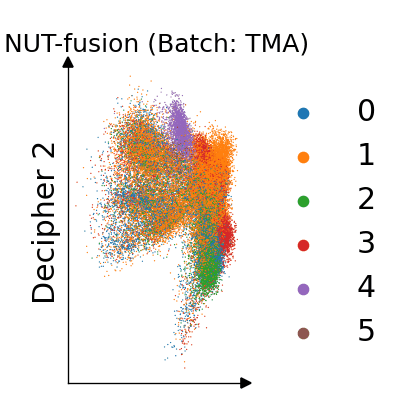

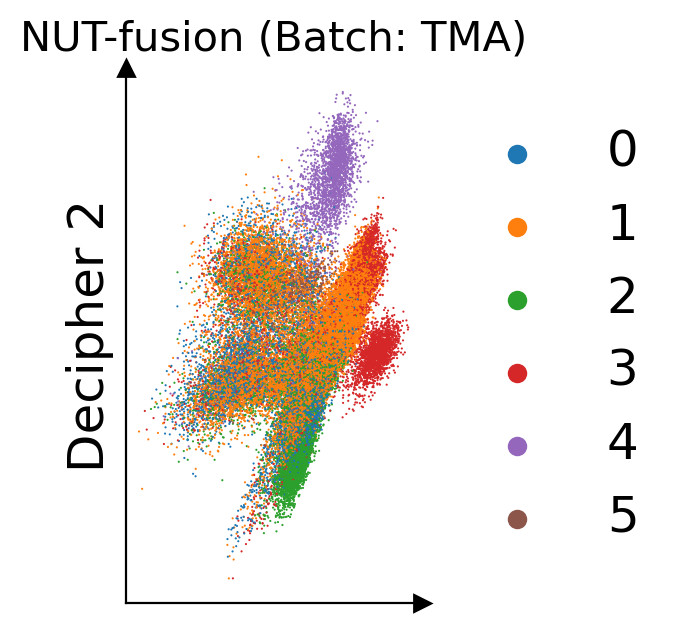

In [ ]:
# Lower learning rate
from decipher.tools._decipher import DecipherConfig
decipher_config3 = DecipherConfig(learning_rate=1e-3, seed = 3)

# Train Decipher
d3, val3 = dc.tl.decipher_train(
    adata_balanced_dc1, decipher_config3, 
    plot_kwargs={"color": "NUT-fusion"}, 
    batch_key="TMA",
    plot_every_k_epochs=5,
)

2026-05-08 00:35:20,812 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 00:35:20,813 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


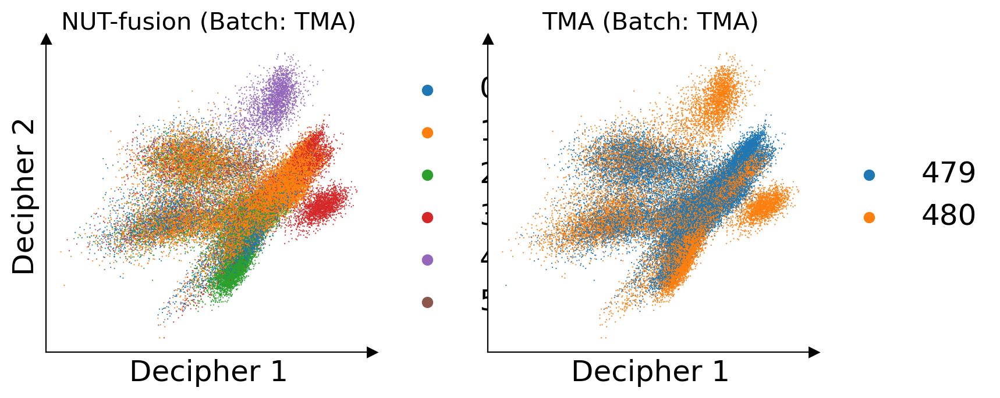

In [ ]:
dc.tl.decipher_rotate_space(
    adata_balanced_dc1,
    v1_col="NUT-fusion",
    v1_order=["0", "1", "2", "3", "4", "5"],
    v2_col="TMA",
    v2_order=["479", "480"],
)
# Decipher 1: ex_group, Decipher 2: TMA
dc.pl.decipher(adata_balanced_dc1, ["NUT-fusion", "TMA"], palette=color_palette);

In [ ]:
adata_balanced_dc1.obsm['decipher_v_seed1'] = adata_balanced_dc1.obsm['decipher_v'].copy()

Epoch 18 (batch 703/703) | | train elbo: 238.04 (last epoch: 238.15) | val ll: 250.59:   2%|▏         | 18/1000 [11:43<10:39:18, 39.06s/it]2026-05-08 00:08:04,103 | INFO : Early stopping has been triggered.
2026-05-08 00:08:04,624 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 00:08:04,625 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-08 00:08:04,628 | INFO : Saving decipher model with run_id 2026-05-08-00-08-04-parallel-angry-block.


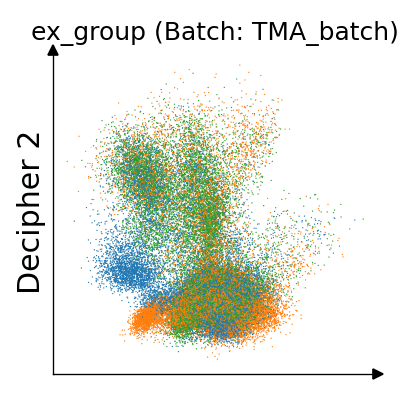

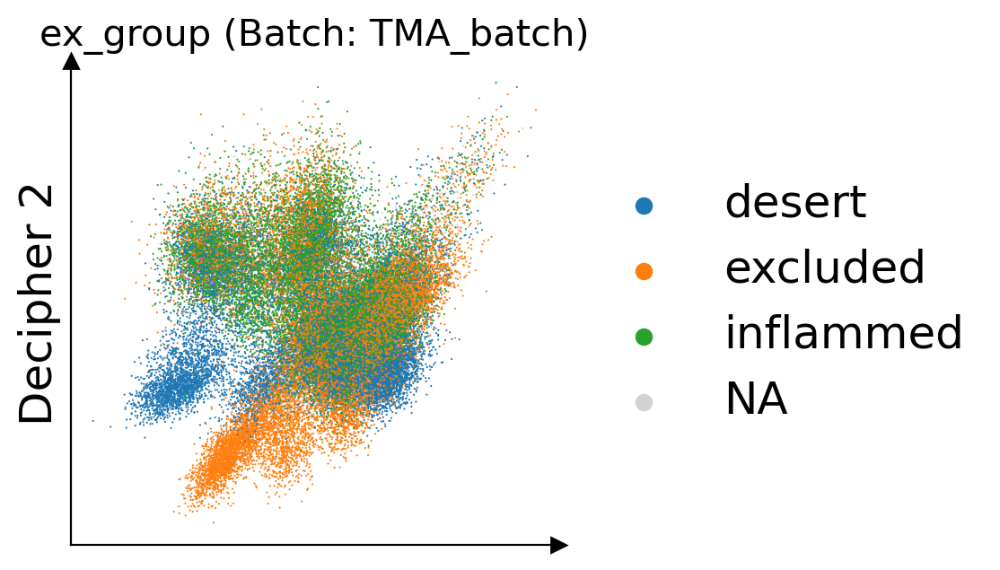

In [ ]:
decipher_config2 = DecipherConfig(learning_rate=1e-3, seed = 2)

# Train Decipher
d2, val2 = dc.tl.decipher_train(
    adata_balanced_dc1, decipher_config2, 
    plot_kwargs={"color": "ex_group"}, 
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

2026-05-08 00:10:50,667 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-08 00:10:50,668 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


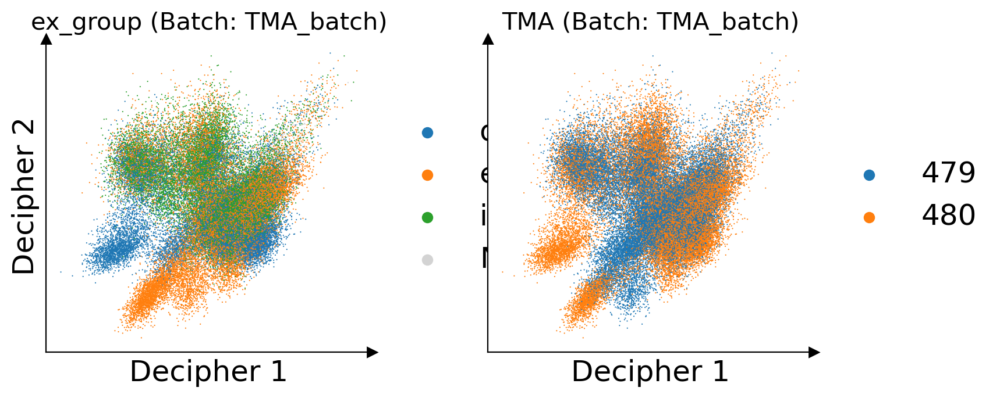

In [ ]:
dc.tl.decipher_rotate_space(
    adata_balanced_dc1,
    v1_col="ex_group",
    v1_order=["desert", "excluded", "inflammed", "NA"],
    v2_col="TMA",
    v2_order=["479", "480"],
)
# Decipher 1: ex_group, Decipher 2: TMA
dc.pl.decipher(adata_balanced_dc1, ["ex_group", "TMA"], palette=color_palette);

adata_balanced_dc1.obsm['decipher_v_seed2'] = adata_balanced_dc1.obsm['decipher_v'].copy()

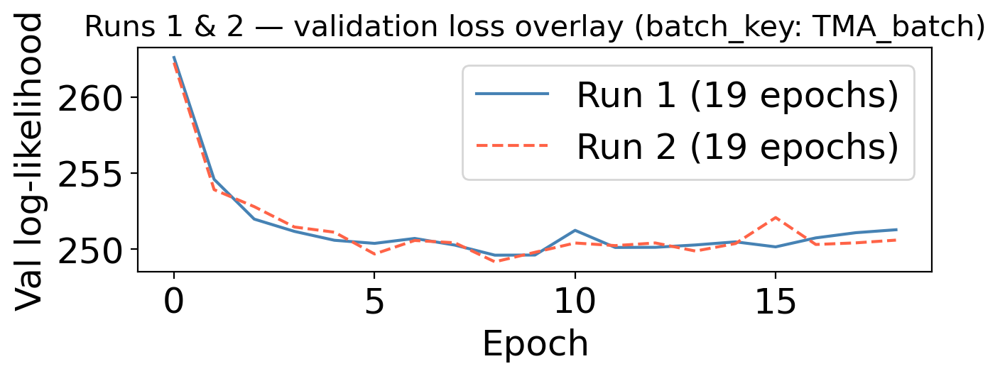

In [ ]:
run1 = adata_balanced_dc1.obsm['decipher_v_seed1']
run2 = adata_balanced_dc1.obsm['decipher_v_seed2']

n_epochs_run1 = len(val1)
n_epochs_run2 = len(val2)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(val1, color="steelblue", linewidth=1.5, label=f"Run 1 ({n_epochs_run1} epochs)")
ax.plot(val2, color="tomato",    linewidth=1.5, label=f"Run 2 ({n_epochs_run2} epochs)",
        linestyle="--")
ax.set_xlabel("Epoch")
ax.set_ylabel("Val log-likelihood")
ax.set_title("Runs 1 & 2 — validation loss overlay (batch_key: TMA_batch)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
    # Repeat

In [ ]:
adata_balanced_dc2 = adata_balanced_dc.copy()

# Ensure the 'decipher' key exists in the metadata
if "decipher" not in adata_balanced_dc2.uns:
    adata_balanced_dc2.uns["decipher"] = {}
    
# Manually stamp the batch_key used during training (e.g., 'TMA_batch')
# This is the step that fixes the "No Batch Correction" title issue
adata_balanced_dc2.uns["decipher"]["config"] = {"batch_key": "sample_id"}

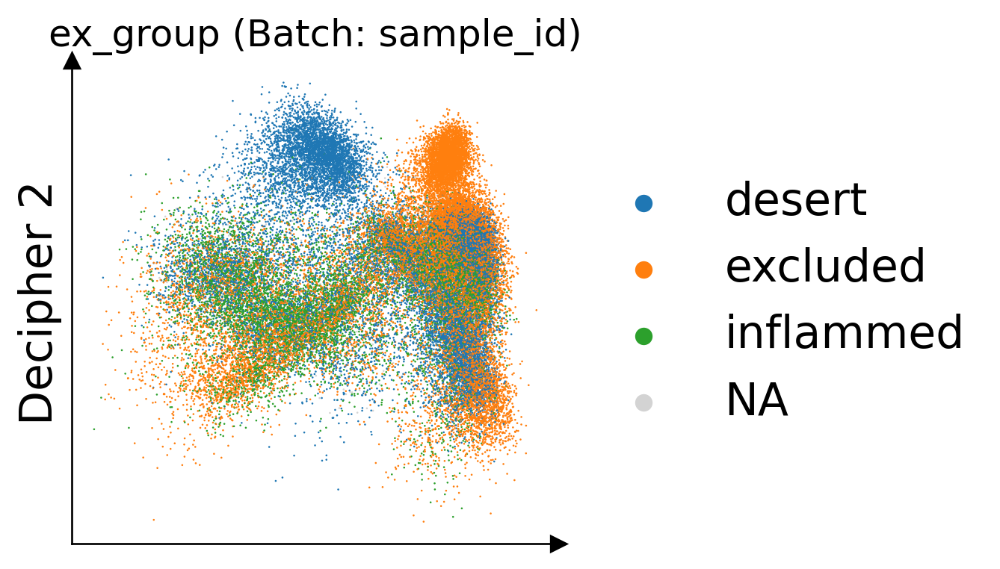

Epoch 3 (batch 521/703) | | train elbo: 241.23 (last epoch: 243.41) | val ll: 250.02:   0%|          | 3/1000 [05:11<28:42:37, 103.67s/it]


KeyboardInterrupt: 

In [ ]:
batch_decipher_config = DecipherConfig(learning_rate=1e-3)
# Train Decipher
d2, val2 = dc.tl.decipher_train(
    batch0_subset_dc, decipher_config, 
    plot_kwargs={"color": "ex_group"}, 
    batch_key="sample_id",
    plot_every_k_epochs=5,
)

In [ ]:
adata_balanced_dc3 = adata_balanced_dc.copy()

# Ensure the 'decipher' key exists in the metadata
if "decipher" not in adata_balanced_dc3.uns:
    adata_balanced_dc3.uns["decipher"] = {}
    
# Manually stamp the batch_key used during training (e.g., 'TMA_batch')
# This is the step that fixes the "No Batch Correction" title issue
adata_balanced_dc3.uns["decipher"]["config"] = {"batch_key": "TMA_batch"}

Epoch 17 (batch 703/703) | | train elbo: 238.91 (last epoch: 238.95) | val ll: 251.91:   2%|▏         | 17/1000 [21:45<20:58:13, 76.80s/it]2026-04-29 14:17:55,003 | INFO : Early stopping has been triggered.
2026-04-29 14:17:56,028 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-04-29 14:17:56,029 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-04-29 14:17:56,032 | INFO : Saving decipher model with run_id 2026-04-29-14-17-56-cyclic-maroon-burger.


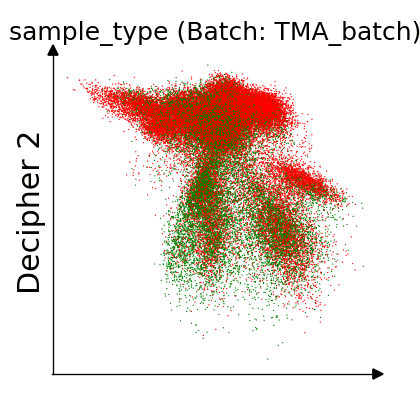

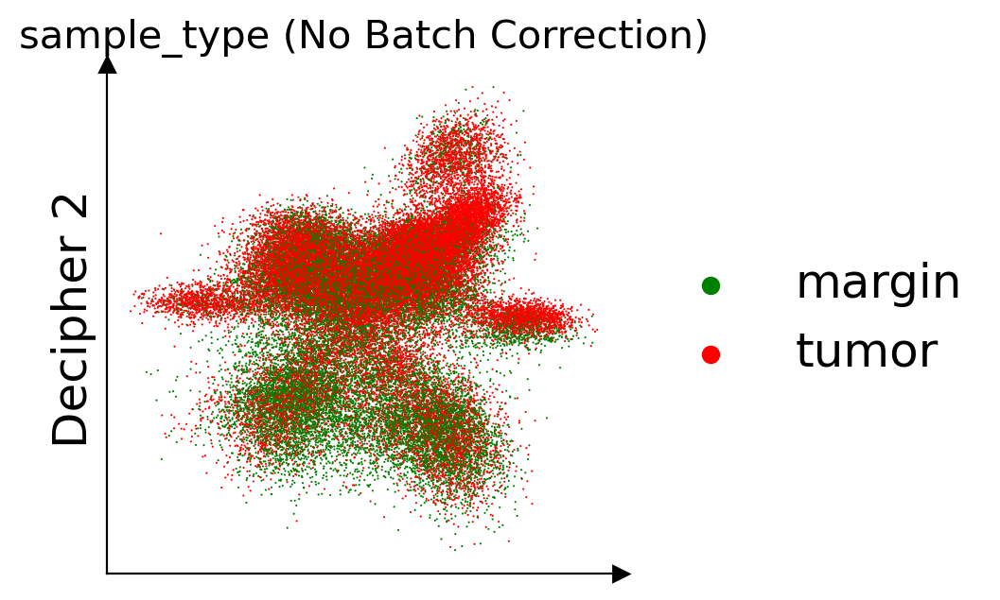

In [ ]:
# Train Decipher
d3, val3 = dc.tl.decipher_train(
    adata_balanced_dc3, decipher_config, 
    plot_kwargs={"color": "sample_type"}, 
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

# Tune

## STEP 1A — RUN 1: fit Decipher with TMA_batch correction

Epoch 17 (batch 703/703) | | train elbo: 238.91 (last epoch: 238.95) | val ll: 251.91:   2%|▏         | 17/1000 [07:49<7:32:37, 27.63s/it]2026-05-06 02:18:42,325 | INFO : Early stopping has been triggered.
2026-05-06 02:18:43,132 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-06 02:18:43,133 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-06 02:18:43,136 | INFO : Saving decipher model with run_id 2026-05-06-02-18-43-lower-ecru-cuisine.


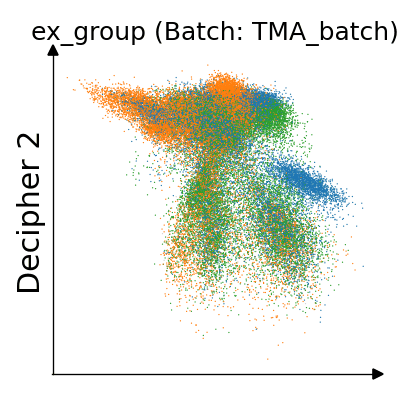

TypeError: object of type 'Decipher' has no len()

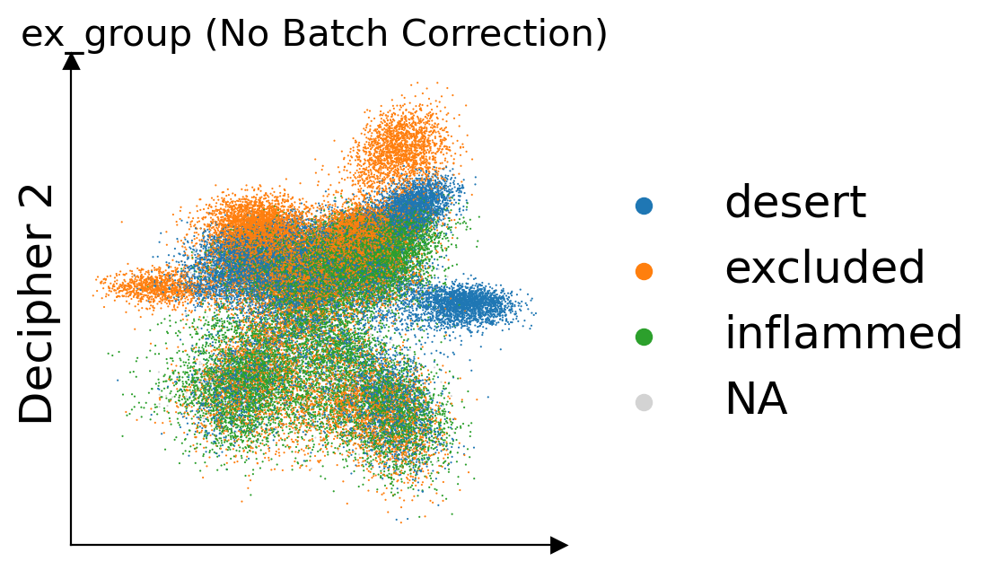

In [ ]:
adata_run1 = adata_balanced_dc.copy()
if "decipher" not in adata_run1.uns:
    adata_run1.uns["decipher"] = {}
adata_run1.uns["decipher"]["config"] = {"batch_key": "TMA_batch"}

decipher_config = DecipherConfig(learning_rate=1e-3)

print("\n" + "="*60)
print("RUN 1 — batch_key: TMA_batch")
print("="*60)

d1, val1 = dc.tl.decipher_train(
    adata_run1,
    decipher_config,
    plot_kwargs={"color": "ex_group"},   # your primary covariate of interest
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

# Save v-space immediately after run 1
v_run1 = adata_run1.obsm["decipher_v"].copy()

In [ ]:
# ── Check 1a: did early stopping fire? ───────────────────────────────────────
n_epochs_run1 = len(val1)
early_stopped_run1 = n_epochs_run1 < decipher_config.n_epochs

print(f"\nRun 1 — epochs completed : {n_epochs_run1} / {decipher_config.n_epochs}")
print(f"Run 1 — early stopping   : {early_stopped_run1}")
print(f"Run 1 — final val ll     : {val1[-1]:.2f}")

if not early_stopped_run1:
    print("  ⚠ WARNING: ran to max epochs — model may not have converged.")
else:
    print("  ✓ Early stopping triggered — model converged.")
    
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(run1, color="steelblue", linewidth=1.5, label=f"Run 1 ({n_epochs_run1} epochs)")
ax.plot(run2, color="tomato",    linewidth=1.5, label=f"Run 2 ({n_epochs_run2} epochs)",
        linestyle="--")
ax.set_xlabel("Epoch")
ax.set_ylabel("Val log-likelihood")
ax.set_title("Runs 1 & 2 — validation loss overlay (batch_key: TMA_batch)")
ax.legend()
plt.tight_layout()
plt.show()


Run 1 — epochs completed : 18 / 1000
Run 1 — early stopping   : True
Run 1 — final val ll     : 251.91
  ✓ Early stopping triggered — model converged.


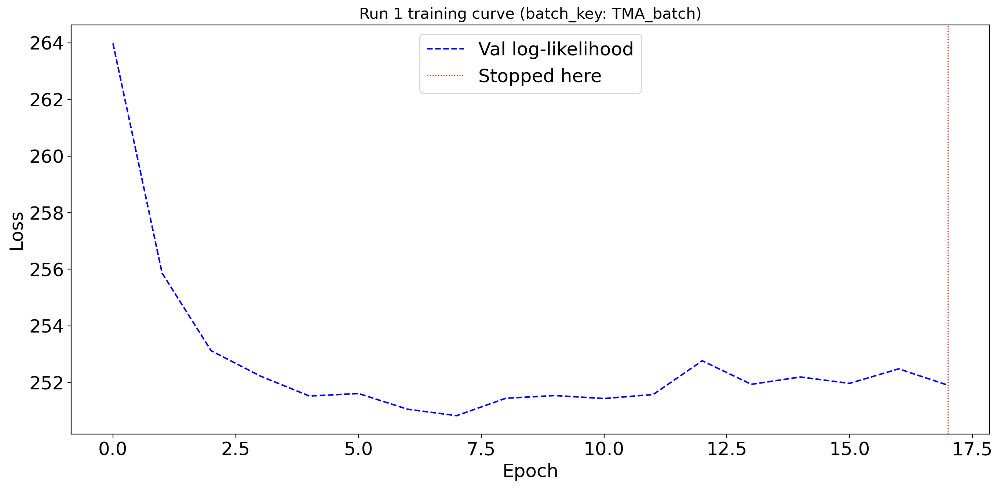

In [ ]:
# ── Plot run 1 training curve ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(val1,  label="Val log-likelihood", color="blue", linestyle="--", linewidth=1.5)
ax.axvline(n_epochs_run1 - 1, color="red", linestyle=":", linewidth=1, label="Stopped here")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Run 1 training curve (batch_key: TMA_batch)")
ax.legend()
plt.tight_layout()
plt.show()


## STEP 1B — RUN 2: same config, same data — reproducibility check

Epoch 17 (batch 703/703) | | train elbo: 238.91 (last epoch: 238.95) | val ll: 251.91:   2%|▏         | 17/1000 [55:55<53:53:25, 197.36s/it]2026-05-06 03:23:09,351 | INFO : Early stopping has been triggered.
2026-05-06 03:23:10,139 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-06 03:23:10,141 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-06 03:23:10,145 | INFO : Saving decipher model with run_id 2026-05-06-03-23-10-crispy-emerald-exponential.


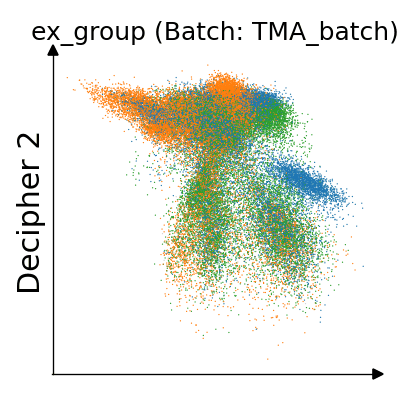


Run 2 — epochs completed : 18 / 1000
Run 2 — early stopping   : True
Run 2 — final val ll     : 251.91
  ✓ Early stopping triggered — model converged.


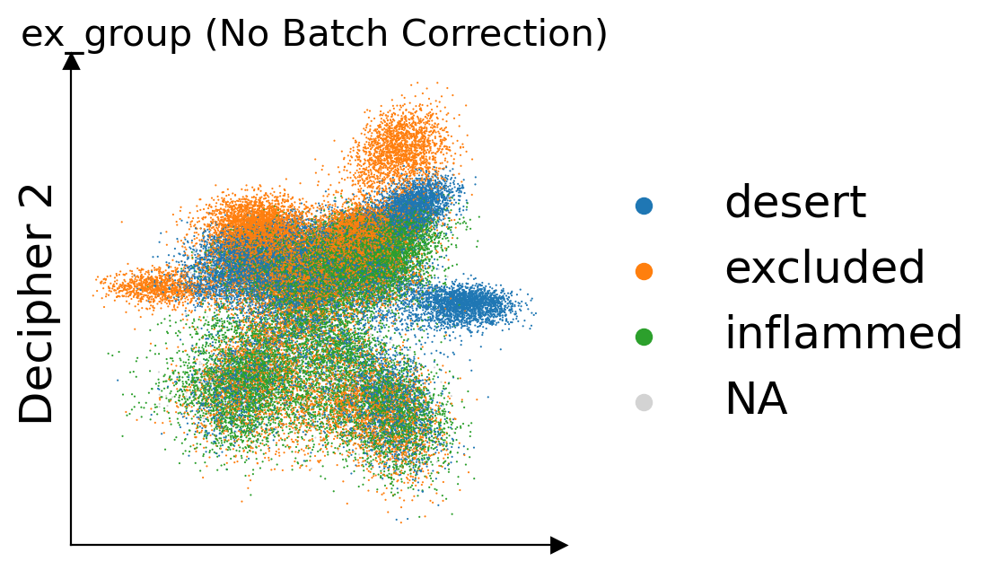

In [ ]:
adata_run2 = adata_balanced_dc.copy()
if "decipher" not in adata_run2.uns:
    adata_run2.uns["decipher"] = {}
adata_run2.uns["decipher"]["config"] = {"batch_key": "TMA_batch"}

d2, val2 = dc.tl.decipher_train(
    adata_run2,
    decipher_config,
    plot_kwargs={"color": "ex_group"},
    batch_key="TMA_batch",
    plot_every_k_epochs=5,
)

# val2 is the only programmatic access to training history
v_run2 = adata_run2.obsm["decipher_v"].copy()

n_epochs_run2 = len(val2)
early_stopped_run2 = n_epochs_run2 < decipher_config.n_epochs

print(f"\nRun 2 — epochs completed : {n_epochs_run2} / {decipher_config.n_epochs}")
print(f"Run 2 — early stopping   : {early_stopped_run2}")
print(f"Run 2 — final val ll     : {val2[-1]:.2f}")

if not early_stopped_run2:
    print("  ⚠ WARNING: ran to max epochs — model may not have converged.")
else:
    print("  ✓ Early stopping triggered — model converged.")

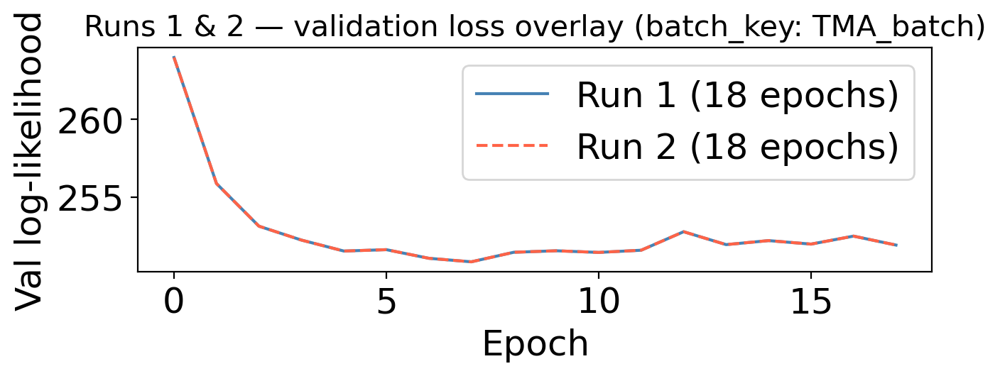

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(val1, color="steelblue", linewidth=1.5, label=f"Run 1 ({n_epochs_run1} epochs)")
ax.plot(val2, color="tomato",    linewidth=1.5, label=f"Run 2 ({n_epochs_run2} epochs)",
        linestyle="--")
ax.set_xlabel("Epoch")
ax.set_ylabel("Val log-likelihood")
ax.set_title("Runs 1 & 2 — validation loss overlay (batch_key: TMA_batch)")
ax.legend()
plt.tight_layout()
plt.show()

## STEP 1C — Consistency check: pairwise distance correlation

In [ ]:
from scipy.spatial.distance import cdist

n_sample = min(500, adata_run1.n_obs)
rng = np.random.default_rng(0)
idx = rng.choice(adata_run1.n_obs, n_sample, replace=False)

dist1 = cdist(v_run1[idx], v_run1[idx])
dist2 = cdist(v_run2[idx], v_run2[idx])

tri = np.triu_indices(n_sample, k=1)
corr = np.corrcoef(dist1[tri], dist2[tri])[0, 1]

print(f"\nPairwise distance correlation (run 1 vs run 2): r = {corr:.3f}")
if corr > 0.90:
    print("  ✓ GOOD: highly consistent latent structure across runs.")
elif corr > 0.70:
    print("  ~ MARGINAL: inspect v-space plots carefully before proceeding.")
else:
    print("  ⚠ WARNING: runs produce very different latent spaces.")
    print("    Troubleshoot: check data prep, rounding, or adjust beta.")


Pairwise distance correlation (run 1 vs run 2): r = 1.000
  ✓ GOOD: highly consistent latent structure across runs.


## STEP 2

In [ ]:
# ── 2A: Subset to tumor cells only ───────────────────────────────────────────
adata_tumor = adata_run1[adata_run1.obs["cell_type_L0"] == "tumor"].copy()

print("Tumor cell count:", adata_tumor.n_obs)
print("\nExclusion group distribution:")
print(adata_tumor.obs["ex_group"].value_counts())
print("\nSample type distribution:")
print(adata_tumor.obs["sample_type"].value_counts())

Tumor cell count: 35414

Exclusion group distribution:
ex_group
excluded     13374
desert       11054
inflammed     8843
Name: count, dtype: int64

Sample type distribution:
sample_type
tumor     26238
margin     9176
Name: count, dtype: int64


## STEP 2B: Quantify batch effect per confounder using silhouette scores ──────────

In [ ]:
adata_tumor_balanced_dc1.shape

(50000, 423)

In [ ]:
adata_tumor_balanced_dc1.layers

Layers with keys: counts, log_counts, norm_log_counts, my_log_counts

In [ ]:
# Before choosing what to correct for, measure which covariates actually drive
# separation in the v-space. High silhouette = strong separation = bigger effect.

from sklearn.metrics import silhouette_score

v = adata_tumor_balanced_dc1.obsm['decipher_v_seed1']

# Only score covariates with at least 2 unique values and no NaNs
covariates_to_score = {
    "TMA"   : adata_tumor_balanced_dc1.obs["TMA"].astype(str),
    "ex_group"    : adata_tumor_balanced_dc1.obs["ex_group"].astype(str),
    "sample_id" : adata_tumor_balanced_dc1.obs["sample_id"].astype(str),
    "NUT-fusion" : adata_tumor_balanced_dc1.obs["NUT-fusion"].astype(str),
    "cell_type_L1": adata_tumor_balanced_dc1.obs["cell_type_L1"].astype(str),
    "cell_type_general": adata_tumor_balanced_dc1.obs["cell_type_general"].astype(str),
    "biopsy_site" : adata_tumor_balanced_dc1.obs["biopsy_site"].astype(str),
    "biopsy_site_classification" : adata_tumor_balanced_dc1.obs["biopsy_site_classification"].astype(str),
}

print("\n── Silhouette scores in v-space (higher = stronger separation) ──────────")
silhouette_results = {}
for name, labels in covariates_to_score.items():
    # Drop NaN rows
    mask = labels != "nan"
    if labels[mask].nunique() < 2:
        print(f"  {name:<20} skipped (< 2 unique values)")
        continue
    score = silhouette_score(v[mask], labels[mask], sample_size=5000, random_state=42)
    silhouette_results[name] = score
    print(f"  {name:<25} silhouette = {score:.4f}")  



── Silhouette scores in v-space (higher = stronger separation) ──────────
  TMA                       silhouette = 0.0620
  ex_group                  silhouette = -0.0104
  sample_id                 silhouette = -0.2532
  NUT-fusion                silhouette = -0.0639
  cell_type_L1              silhouette = -0.2065
  cell_type_general         silhouette = -0.1160
  biopsy_site               silhouette = -0.2255
  biopsy_site_classification silhouette = 0.0111


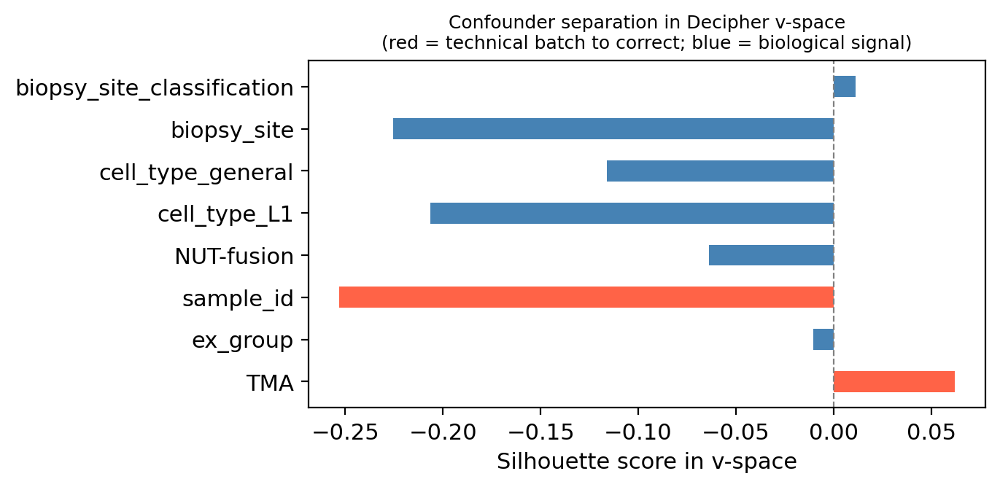

In [ ]:
technical = {"TMA", "sample_id"}  # red = technical batch

fig, ax = plt.subplots(figsize=(7, 3.5))
plt.rcParams.update({'font.size': 11})

names  = list(silhouette_results.keys())
scores = list(silhouette_results.values())
colors = ["tomato" if n in technical else "steelblue" for n in names]

bars = ax.barh(names, scores, color=colors, edgecolor="none", height=0.5)
ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_xlabel("Silhouette score in v-space")
ax.set_title("Confounder separation in Decipher v-space\n"
             "(red = technical batch to correct; blue = biological signal)", fontsize=9)
plt.tight_layout()
plt.show()

# PCA 

In [ ]:
import scanpy as sc
import numpy as np
from sklearn.metrics import silhouette_score

# ── 1. Copy and set .X to the normalized layer ───────────────────────────────
adata_pca = adata_tumor_balanced_dc.copy()
adata_pca.X = adata_pca.layers["norm_log_counts"]

# ── 2. Scale before PCA ──────────────────────────────────────────────────────
sc.pp.scale(adata_pca, max_value=10)

# ── 3. PCA ───────────────────────────────────────────────────────────────────
sc.tl.pca(adata_pca, n_comps=50, svd_solver="arpack")

pca_embedding = adata_pca.obsm["X_pca"]  # shape: (n_cells, 50)

# ── 4. Silhouette scores in PCA space ────────────────────────────────────────
covariates_to_score = {
    "TMA"                        : adata_tumor_balanced_dc1.obs["TMA"].astype(str),
    "ex_group"                   : adata_tumor_balanced_dc1.obs["ex_group"].astype(str),
    "sample_id"                  : adata_tumor_balanced_dc1.obs["sample_id"].astype(str),
    "NUT-fusion"                 : adata_tumor_balanced_dc1.obs["NUT-fusion"].astype(str),
    "cell_type_L1"               : adata_tumor_balanced_dc1.obs["cell_type_L1"].astype(str),
    "cell_type_general"          : adata_tumor_balanced_dc1.obs["cell_type_general"].astype(str),
    "biopsy_site"                : adata_tumor_balanced_dc1.obs["biopsy_site"].astype(str),
    "biopsy_site_classification" : adata_tumor_balanced_dc1.obs["biopsy_site_classification"].astype(str),
}

print("\n── Silhouette scores in PCA space (pre-Decipher baseline) ──────────────")
pca_silhouette_results = {}
for name, labels in covariates_to_score.items():
    mask = labels != "nan"
    if labels[mask].nunique() < 2:
        print(f"  {name:<25} skipped (< 2 unique values)")
        continue
    score = silhouette_score(pca_embedding[mask], labels[mask], sample_size=5000, random_state=42)
    pca_silhouette_results[name] = score
    print(f"  {name:<25} silhouette = {score:.4f}")

# ── 5. Side-by-side comparison ───────────────────────────────────────────────
print("\n── PCA vs v-space comparison ────────────────────────────────────────────")
print(f"  {'covariate':<25} {'PCA':>8}  {'v-space':>8}  {'delta':>8}")
print(f"  {'-'*25} {'-'*8}  {'-'*8}  {'-'*8}")
for name in pca_silhouette_results:
    pca_s = pca_silhouette_results.get(name, float("nan"))
    v_s   = silhouette_results.get(name, float("nan"))
    delta = v_s - pca_s
    print(f"  {name:<25} {pca_s:>8.4f}  {v_s:>8.4f}  {delta:>+8.4f}")


── Silhouette scores in PCA space (pre-Decipher baseline) ──────────────
  TMA                       silhouette = 0.0302
  ex_group                  silhouette = 0.0150
  sample_id                 silhouette = 0.0717
  NUT-fusion                silhouette = 0.0364
  cell_type_L1              silhouette = 0.0358
  cell_type_general         silhouette = 0.0662
  biopsy_site               silhouette = 0.0210
  biopsy_site_classification silhouette = 0.0279

── PCA vs v-space comparison ────────────────────────────────────────────
  covariate                      PCA   v-space     delta
  ------------------------- --------  --------  --------
  TMA                         0.0302    0.0620   +0.0318
  ex_group                    0.0150   -0.0104   -0.0255
  sample_id                   0.0717   -0.2532   -0.3249
  NUT-fusion                  0.0364   -0.0639   -0.1003
  cell_type_L1                0.0358   -0.2065   -0.2423
  cell_type_general           0.0662   -0.1160   -0.1821
  biopsy_s

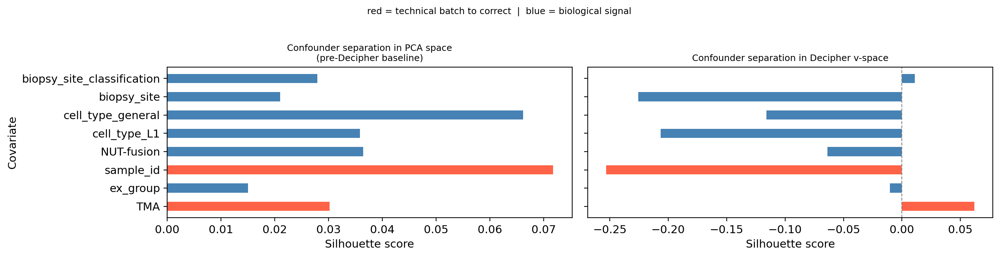

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
plt.rcParams.update({'font.size': 11})

technical = {"TMA", "sample_id"}  # red = technical batch
datasets = [
    (pca_silhouette_results, "Confounder separation in PCA space\n(pre-Decipher baseline)"),
    (silhouette_results,     "Confounder separation in Decipher v-space"),
]

for ax, (results, title) in zip(axes, datasets):
    names  = list(results.keys())
    scores = list(results.values())
    colors = ["tomato" if n in technical else "steelblue" for n in names]

    ax.barh(names, scores, color=colors, edgecolor="none", height=0.5)
    ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
    ax.set_xlabel("Silhouette score")
    ax.set_title(title, fontsize=9)

axes[0].set_ylabel("Covariate")

# shared legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="tomato",    label="Technical (correct)"),
    Patch(facecolor="steelblue", label="Biological (preserve)"),
]

plt.suptitle("red = technical batch to correct  |  blue = biological signal",
             fontsize=9, y=1.01)
plt.tight_layout()
plt.show()

# simulated data

In [ ]:
adata_combined = sc.read_h5ad('simulated_data/concat_adata_may/adata_combined_alpha_0.1_0.3_0.5_0.7_1.0(2).h5ad')
adata_combined.uns["color_palette"] = None
color_palette = None

In [ ]:
print(adata_combined.obs['shift'].unique().tolist())

['0', '0.1', '0.3', '0.5', '0.7', '1.0']


Epoch 204 (batch 24/24) | | train elbo: 122.94 (last epoch: 123.77) | val ll: 136.07:  20%|██        | 204/1000 [04:07<16:05,  1.21s/it]2026-05-14 02:07:24,609 | INFO : Early stopping has been triggered.
2026-05-14 02:07:24,626 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-14 02:07:24,627 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-05-14 02:07:24,631 | INFO : Saving decipher model with run_id 2026-05-14-02-07-24-swarm-burgundy-tartar.


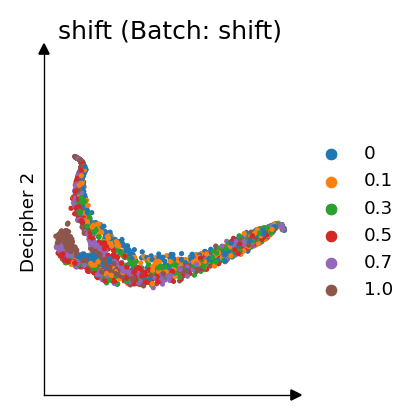

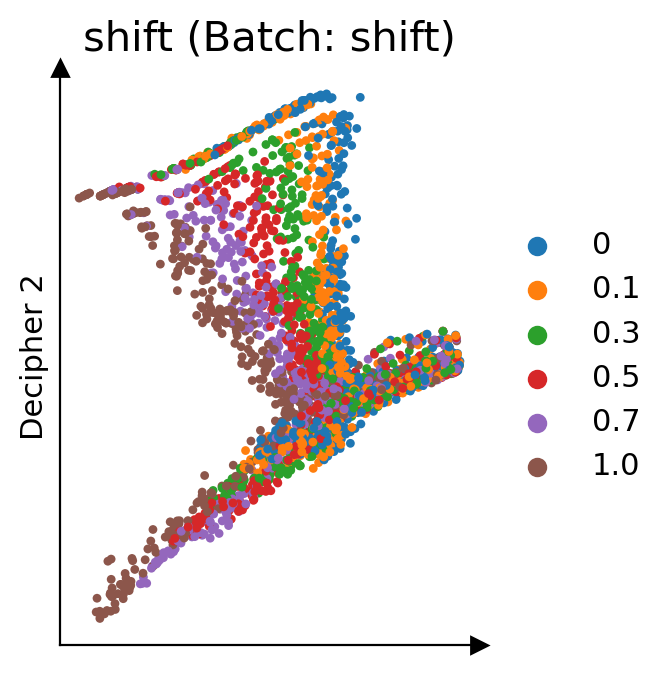

In [ ]:
decipher_config = DecipherConfig(learning_rate=1e-3, seed=1)

# Train Decipher
d1, val1 = dc.tl.decipher_train(
    adata_combined, decipher_config, plot_kwargs= {"color": "shift"}, batch_key="shift",plot_every_k_epochs=5,
)

alpha
0      0.017917
0.1   -0.027240
0.3   -0.054092
0.5   -0.075074
0.7   -0.104447
1.0   -0.112435
Name: silhouette_value, dtype: float32


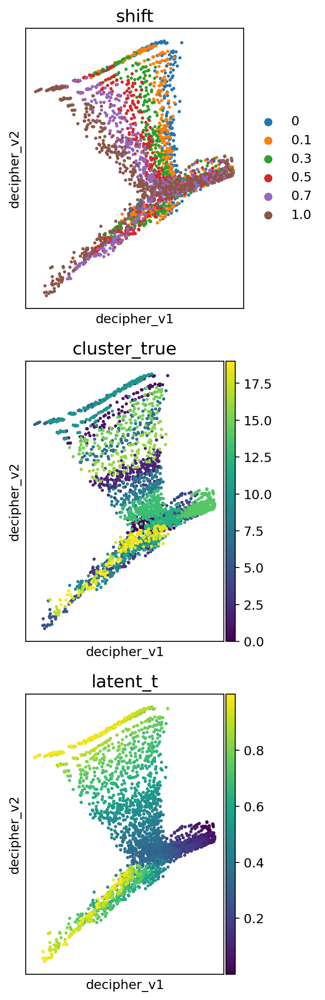

In [ ]:
import logging
import pandas as pd
import scanpy as sc
import os
from sklearn.cluster import KMeans

from matplotlib import pyplot as plt
import seaborn as sns

import matplotlib as mpl

import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.sparse.csgraph import minimum_spanning_tree
from sklearn.metrics import silhouette_samples

suffix = "native_alpha_0.1_0.3_0.5_0.7_1.0"

decipher_z = adata_combined.obsm["decipher_z"]
k_means = KMeans(20)
k_means.fit(decipher_z)
adata_combined.obs["cluster_latent"] = k_means.labels_

aris = {}
for a in adata_combined.obs["shift"].unique():
    mask = adata_combined.obs["shift"] == a
    aris[a] = adjusted_rand_score(
        adata_combined.obs["cluster_true"][mask],
        adata_combined.obs["cluster_latent"][mask],
    )
#print(f"[{suffix}] aris values: {aris}")

shift_labels = adata_combined.obs["shift"]
sil_values = silhouette_samples(decipher_z, shift_labels)
df = pd.DataFrame({"silhouette_value": sil_values, "alpha": shift_labels.values})
print(df.groupby("alpha", observed=True)["silhouette_value"].mean())

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(4, 3*4))
# sc.pl.embedding(adata_combined, basis="decipher_v", color="shift",
#                 show=False, ax=axes[0], size=30)
sc.pl.embedding(adata_combined, basis="decipher_v", color="shift",
                show=False, ax=axes[0], size=30)
sc.pl.embedding(adata_combined, basis="decipher_v", color="cluster_true",
                show=False, ax=axes[1], size=30)
sc.pl.embedding(adata_combined, basis="decipher_v", color="latent_t",
                show=False, ax=axes[2], size=30)
plt.tight_layout()
plt.show()

In [ ]:
# Before choosing what to correct for, measure which covariates actually drive
# separation in the v-space. High silhouette = strong separation = bigger effect.

from sklearn.metrics import silhouette_score

v = adata_combined.obsm['decipher_v'].copy()

# Only score covariates with at least 2 unique values and no NaNs
covariates_to_score = {
    "shift"   : adata_combined.obs["shift"].astype(str),
}

print("\n── Silhouette scores in v-space (higher = stronger separation) ──────────")
silhouette_results = {}
for name, labels in covariates_to_score.items():
    # Drop NaN rows
    mask = labels != "nan"
    if labels[mask].nunique() < 2:
        print(f"  {name:<20} skipped (< 2 unique values)")
        continue
    score = silhouette_score(v[mask], labels[mask], sample_size=5000, random_state=42)
    silhouette_results[name] = score
    print(f"  {name:<25} silhouette = {score:.4f}")  



── Silhouette scores in v-space (higher = stronger separation) ──────────
  shift                     silhouette = -0.0487


## STEP 3


In [ ]:
# ── 3A: Define gene sets (replace/expand with the highlighted genes from Excel) 
undiff_markers = ["SOX2", "MKI67", "MYC"]        # undifferentiated markers
diff_markers   = ["KRT5", "CDKN1A"]              # differentiated markers
# TP63 explicitly excluded per meeting notes

# ── 3B: Check which markers are actually in the Xenium panel ─────────────────
panel_genes = list(adata_run1.var_names)

undiff_present = [g for g in undiff_markers if g in panel_genes]
undiff_missing = [g for g in undiff_markers if g not in panel_genes]
diff_present   = [g for g in diff_markers   if g in panel_genes]
diff_missing   = [g for g in diff_markers   if g not in panel_genes]

print("── Gene panel check ─────────────────────────────────────────────────────")
print(f"  Undifferentiated markers present : {undiff_present}")
print(f"  Undifferentiated markers missing : {undiff_missing}")
print(f"  Differentiated markers present   : {diff_present}")
print(f"  Differentiated markers missing   : {diff_missing}")


── Gene panel check ─────────────────────────────────────────────────────
  Undifferentiated markers present : ['SOX2', 'MKI67', 'MYC']
  Undifferentiated markers missing : []
  Differentiated markers present   : ['KRT5', 'CDKN1A']
  Differentiated markers missing   : []


In [ ]:
import numpy as np

# If data is log-normalized, max should be roughly 6-10
# If data is raw counts, max will be in the hundreds or thousands
print("X max:", adata_run1.X.max())
print("X mean:", adata_run1.X.mean())
print("X min:", adata_run1.X.min())

# Also check if scanpy recorded any preprocessing steps
print("\nadata.uns keys:", list(adata_run1.uns.keys()))

# Check layers — raw counts are often preserved in a layer
print("\nadata.layers:", list(adata_run1.layers.keys()))

X max: 1524
X mean: 0.7430871867612289
X min: 0

adata.uns keys: ['atypical_colors', 'cell_type_L3_corr_colors', 'cell_type_colors', 'ex_group_colors', 'highlight_colors', 'highlight_group_colors', 'leiden', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'sample_id_colors', 'sample_type_colors', 'umap', 'color_palette', 'decipher']

adata.layers: ['counts', 'log_counts']


In [ ]:
# ── 3C: Score genes on the FULL balanced dataset (not just tumor subset) ──────
# sc.tl.score_genes works on normalized expression — use the full adata_run1
# which already has rounded integer counts in .X. Normalize first for scoring.
adata_scored = adata_run1.copy()
sc.pp.normalize_total(adata_scored, target_sum=1e4)
sc.pp.log1p(adata_scored)

if undiff_present:
    sc.tl.score_genes(
        adata_scored,
        gene_list=undiff_present,
        score_name="undiff_score",
        random_state=42,
    )
    print("\nUndifferentiation score added to adata.obs['undiff_score']")

if diff_present:
    sc.tl.score_genes(
        adata_scored,
        gene_list=diff_present,
        score_name="diff_score",
        random_state=42,
    )
    print("Differentiation score added to adata.obs['diff_score']")
    
# ── 3D: Net differentiation score (diff - undiff) ────────────────────────────
if undiff_present and diff_present:
    adata_scored.obs["net_diff_score"] = (
        adata_scored.obs["diff_score"] - adata_scored.obs["undiff_score"]
    )
    print("Net differentiation score added to adata.obs['net_diff_score']")


Undifferentiation score added to adata.obs['undiff_score']
Differentiation score added to adata.obs['diff_score']
Net differentiation score added to adata.obs['net_diff_score']


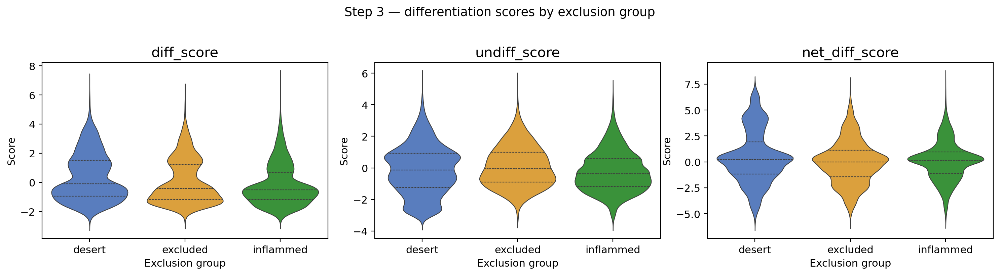

In [ ]:
# ── 3E: Inspect score distributions per exclusion group ──────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

ex_group_order = ["desert", "excluded", "inflammed"]  # your exact strings from adata.obs
ex_palette     = {"desert": "#4878CF", "excluded": "#F5A623", "inflammed": "#2CA02C"}

scores_to_plot = [s for s in ["diff_score", "undiff_score", "net_diff_score"]
                  if s in adata_scored.obs.columns]

fig, axes = plt.subplots(1, len(scores_to_plot), figsize=(5 * len(scores_to_plot), 4))
if len(scores_to_plot) == 1:
    axes = [axes]

for ax, score in zip(axes, scores_to_plot):
    plot_df = adata_scored.obs[["ex_group", score]].dropna()
    # Filter to known ex_group values only
    plot_df = plot_df[plot_df["ex_group"].isin(ex_group_order)]
    sns.violinplot(
        data=plot_df, x="ex_group", y=score,
        order=ex_group_order, palette=ex_palette,
        inner="quartile", ax=ax, linewidth=0.8,
    )
    ax.set_title(score)
    ax.set_xlabel("Exclusion group")
    ax.set_ylabel("Score")

plt.suptitle("Step 3 — differentiation scores by exclusion group", y=1.02)
plt.tight_layout()
plt.show()

Tumor cells: 35,414

Exclusion group breakdown:
ex_group
excluded     13374
desert       11054
inflammed     8843
Name: count, dtype: int64

X max:  1524.000
X mean: 0.798

Data appears to be raw counts — normalizing from counts layer...

Undiff markers in panel : ['SOX2', 'MKI67', 'MYC']
Diff markers in panel   : ['KRT5', 'CDKN1A']


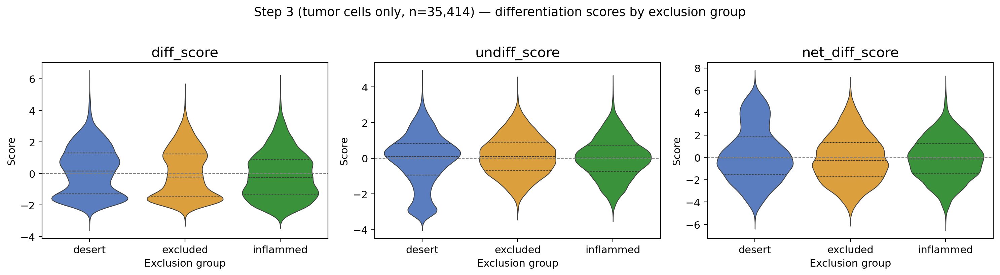


── Median scores per exclusion group (tumor cells only) ─────────────────

  diff_score:
    desert       median = +0.158  (n=11,054)
    excluded     median = -0.233  (n=13,374)
    inflammed    median = -0.259  (n=8,843)

  undiff_score:
    desert       median = +0.096  (n=11,054)
    excluded     median = +0.097  (n=13,374)
    inflammed    median = +0.008  (n=8,843)

  net_diff_score:
    desert       median = -0.047  (n=11,054)
    excluded     median = -0.302  (n=13,374)
    inflammed    median = -0.129  (n=8,843)


In [ ]:
# ── Subset to tumor cells only ────────────────────────────────────────────────
adata_tumor_scored = adata_run1[adata_run1.obs["cell_type_L0"] == "tumor"].copy()

print(f"Tumor cells: {adata_tumor_scored.n_obs:,}")
print("\nExclusion group breakdown:")
print(adata_tumor_scored.obs["ex_group"].value_counts())

# ── Check normalization state (same check as before) ─────────────────────────
print(f"\nX max:  {adata_tumor_scored.X.max():.3f}")
print(f"X mean: {adata_tumor_scored.X.mean():.3f}")

# ── Score genes on tumor cells only ──────────────────────────────────────────
# If X.max() is already ~6-10 (log-normalized), skip the normalize/log1p block.
# If X.max() is in the hundreds, restore from counts layer first.

if adata_tumor_scored.X.max() > 20:
    print("\nData appears to be raw counts — normalizing from counts layer...")
    adata_tumor_scored.X = adata_tumor_scored.layers['counts'].copy()
    sc.pp.normalize_total(adata_tumor_scored, target_sum=1e4)
    sc.pp.log1p(adata_tumor_scored)
else:
    print("\nData appears already log-normalized — skipping normalization.")

# ── Re-check which markers are present in the panel ──────────────────────────
panel_genes    = list(adata_tumor_scored.var_names)
undiff_present = [g for g in undiff_markers if g in panel_genes]
diff_present   = [g for g in diff_markers   if g in panel_genes]

print(f"\nUndiff markers in panel : {undiff_present}")
print(f"Diff markers in panel   : {diff_present}")

# ── Compute scores ────────────────────────────────────────────────────────────
if undiff_present:
    sc.tl.score_genes(
        adata_tumor_scored,
        gene_list=undiff_present,
        score_name="undiff_score",
        random_state=42,
    )

if diff_present:
    sc.tl.score_genes(
        adata_tumor_scored,
        gene_list=diff_present,
        score_name="diff_score",
        random_state=42,
    )

if undiff_present and diff_present:
    adata_tumor_scored.obs["net_diff_score"] = (
        adata_tumor_scored.obs["diff_score"] - adata_tumor_scored.obs["undiff_score"]
    )

# ── Plot ──────────────────────────────────────────────────────────────────────
ex_group_order = ["desert", "excluded", "inflammed"]
ex_palette     = {"desert": "#4878CF", "excluded": "#F5A623", "inflammed": "#2CA02C"}

scores_to_plot = [s for s in ["diff_score", "undiff_score", "net_diff_score"]
                  if s in adata_tumor_scored.obs.columns]

fig, axes = plt.subplots(1, len(scores_to_plot), figsize=(5 * len(scores_to_plot), 4))
if len(scores_to_plot) == 1:
    axes = [axes]

for ax, score in zip(axes, scores_to_plot):
    plot_df = adata_tumor_scored.obs[["ex_group", score]].dropna()
    plot_df = plot_df[plot_df["ex_group"].isin(ex_group_order)]
    sns.violinplot(
        data=plot_df, x="ex_group", y=score,
        order=ex_group_order, palette=ex_palette,
        inner="quartile", ax=ax, linewidth=0.8,
    )
    ax.set_title(score)
    ax.set_xlabel("Exclusion group")
    ax.set_ylabel("Score")
    ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

plt.suptitle(
    f"Step 3 (tumor cells only, n={adata_tumor_scored.n_obs:,}) — "
    f"differentiation scores by exclusion group",
    y=1.02
)
plt.tight_layout()
plt.show()

# ── Quick stats summary ───────────────────────────────────────────────────────
print("\n── Median scores per exclusion group (tumor cells only) ─────────────────")
for score in scores_to_plot:
    print(f"\n  {score}:")
    for group in ex_group_order:
        mask = adata_tumor_scored.obs["ex_group"] == group
        median = adata_tumor_scored.obs.loc[mask, score].median()
        n      = mask.sum()
        print(f"    {group:<12} median = {median:+.3f}  (n={n:,})")

## STEP 4

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# STEP 4 — Apply rotation and map scores onto v-space
# Rotate Decipher 1 → differentiation axis (undiff → diff)
# Rotate Decipher 2 → exclusion group axis (desert → excluded → inflamed)
# Then visualize all covariates on the rotated v-space
# ═══════════════════════════════════════════════════════════════════════════════

# ── 4A: Apply rotation ────────────────────────────────────────────────────────
# Uses the scored adata so scores are available immediately after rotation.
# v1_order: undiff → diff (following the trajectory direction Josh described)
# v2_order: desert → excluded → inflamed (the immune exclusion progression)

2026-05-06 04:31:11,577 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-05-06 04:31:11,585 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


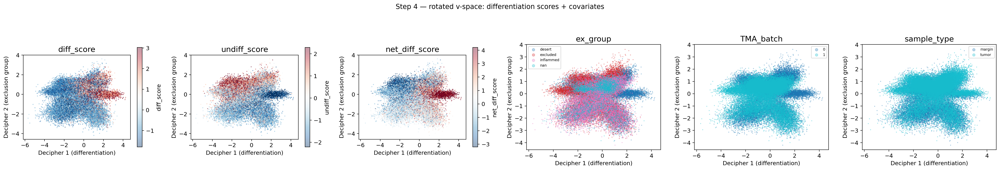

In [ ]:
dc.tl.decipher_rotate_space(
    adata_scored,
    v1_col="cell_type_L1",         # proxy for differentiation state via cell type
    v1_order=["tumor"],             # or supply diff_score as a continuous guide
    v2_col="ex_group",
    v2_order=["desert", "excluded", "inflammed"],
)

# ── 4B: Map differentiation scores onto the rotated v-space ──────────────────
v_rot = adata_scored.obsm["decipher_v"]

scores_for_map = [s for s in ["diff_score", "undiff_score", "net_diff_score"]
                  if s in adata_scored.obs.columns]
all_plot_cols = scores_for_map + ["ex_group", "TMA_batch", "sample_type"]

n_cols = len(all_plot_cols)
fig, axes = plt.subplots(1, n_cols, figsize=(4.5 * n_cols, 4.5))

for ax, col in zip(axes, all_plot_cols):
    vals = adata_scored.obs[col]
    is_continuous = vals.dtype in [float, "float32", "float64"]

    if is_continuous:
        sc_plot = ax.scatter(
            v_rot[:, 0], v_rot[:, 1],
            c=vals, cmap="RdBu_r", s=1, alpha=0.4, rasterized=True,
            vmin=np.percentile(vals.dropna(), 5),
            vmax=np.percentile(vals.dropna(), 95),
        )
        plt.colorbar(sc_plot, ax=ax, shrink=0.7, label=col)
    else:
        labels = vals.astype(str).values
        unique = sorted(set(labels))
        cmap   = plt.cm.tab10(np.linspace(0, 1, len(unique)))
        for label, color in zip(unique, cmap):
            mask = labels == label
            ax.scatter(v_rot[mask, 0], v_rot[mask, 1],
                       s=1, alpha=0.3, color=color, label=label, rasterized=True)
        if len(unique) <= 8:
            ax.legend(markerscale=5, fontsize=7, loc="best")

    ax.set_xlabel("Decipher 1 (differentiation)")
    ax.set_ylabel("Decipher 2 (exclusion group)")
    ax.set_title(col)
    ax.set_aspect("equal")

plt.suptitle("Step 4 — rotated v-space: differentiation scores + covariates", y=1.02)
plt.tight_layout()
plt.show()


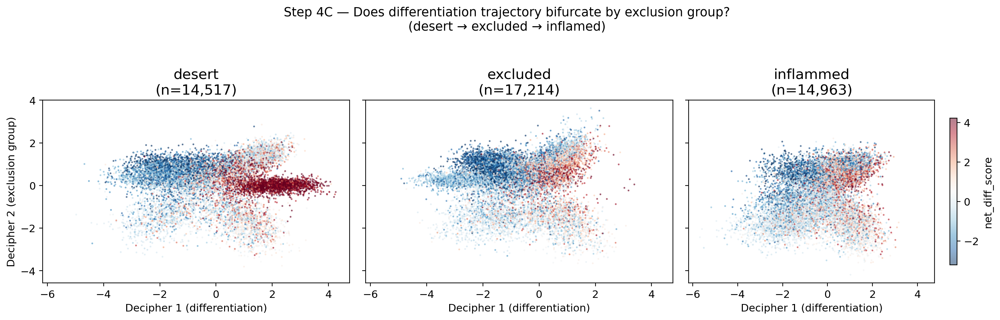

In [ ]:

# ── 4C: Core research question — does the trajectory bifurcate by ex_group? ──
# Plot each exclusion group separately to see if desert/excluded/inflamed
# cells occupy different regions of the differentiation trajectory.

fig, axes = plt.subplots(1, len(ex_group_order), figsize=(5 * len(ex_group_order), 4.5),
                         sharey=True, sharex=True)

if "net_diff_score" in adata_scored.obs.columns:
    score_col = "net_diff_score"
elif "diff_score" in adata_scored.obs.columns:
    score_col = "diff_score"

vmin = np.percentile(adata_scored.obs[score_col].dropna(), 5)
vmax = np.percentile(adata_scored.obs[score_col].dropna(), 95)

for ax, group in zip(axes, ex_group_order):
    mask = adata_scored.obs["ex_group"] == group
    sc_plot = ax.scatter(
        v_rot[mask, 0], v_rot[mask, 1],
        c=adata_scored.obs.loc[mask, score_col],
        cmap="RdBu_r", s=1, alpha=0.5, rasterized=True,
        vmin=vmin, vmax=vmax,
    )
    ax.set_title(f"{group}\n(n={mask.sum():,})")
    ax.set_xlabel("Decipher 1 (differentiation)")
    if ax == axes[0]:
        ax.set_ylabel("Decipher 2 (exclusion group)")

plt.colorbar(sc_plot, ax=axes[-1], shrink=0.8, label=score_col)
plt.suptitle(
    "Step 4C — Does differentiation trajectory bifurcate by exclusion group?\n"
    "(desert → excluded → inflamed)",
    y=1.04
)
plt.tight_layout()
plt.show()

# Delete

### Rotate and flip the learned latent space to align it with the mechanisms of interest
We would ideally want `Decipher 1` to capture blast progression, and `Decipher 2` to discriminate `Healthy` and the AML sample.

In [ ]:
adata_subset.obs.columns

Index(['centroid_x', 'centroid_y', 'centroid_z', 'fov', 'cluster', 'volume',
       'population', 'cell_num', 'Unnamed: 0', 'sample_num', 'sample_id',
       'sample_type', 'TMA', 'batch', 'log10_total_counts', 'leiden',
       'density_status', 'atypical', 'deviation_score', 'log_lib_size',
       'cell_type', 'TMA_ID', 'OS_days',
       'survival sample date to death (days)',
       'treatment_(0= no treatment before biopsy; 1=treatment before biopsy)',
       'biopsy_site',
       'biopsy_site_classification (0 = unkwn; 1 = head and neck; 2 = thoracic; 3 = non-head and neck or thoracic; 4 = LN)',
       'sample site: primary vs met',
       'primary site classification (0 = unkwn; 1 = head and neck; 2 = thoracic; 3 = non-head and neck or thoracic)',
       'age_(yrs)', 'sex', 'PDL1 (TPS%)', 'PDL1: 0 = <1%; 1 = >=1%',
       'NUT-fusion: 0 = unkwn; 1 = BRD4-NUT; 2 = BRD3-NUT; 3 = NSD3-NUT; 4 = ZNF532-NUT; 5 = ZNF592-NUT',
       'note:', 'Registry participant? (YES/n)', 'NC registry 

In [ ]:
adata_subset.obs['cell_type'].value_counts()

cell_type
tumor             206583
fibroblast         20290
macrophage         11949
endothelial        11352
mixed_immune        9237
plasma b            7572
mixed_APC           7088
DC                  4051
epithelial          3963
monocyte            2595
mesenchymal         1012
cDC2                 950
T reg                915
b cell               733
CD4 Th 17            702
CD8 T effector       665
NK cell              604
mixed_stromal        353
cDC1                 319
CD4 Th 1             279
t cell               264
CD8 T cm             247
neutrophil           212
pDC                   69
CD4 Tfh               64
Name: count, dtype: int64

In [ ]:
adata_subset.obs['sample_type'].value_counts()

sample_type
tumor     210516
margin     81552
Name: count, dtype: int64

In [ ]:
adata_subset.obs['ex_group'].value_counts()

ex_group
excluded     129292
desert       104917
inflammed     51756
Name: count, dtype: int64

In [ ]:
dc.tl.decipher_rotate_space(
    adata_dc,
    v1_col="ex_group",
    v1_order=["excluded", "desert", "inflammed"],
    v2_col="sample_type",
    v2_order=["tumor", "margin"],
)
dc.pl.decipher(adata_dc, ["cell_type", "sample_type"], palette=color_palette);

ValueError: No decipher model has been saved for this AnnData object.

### We now cluster the cells using the `decipher_z` representation, and compute trajectories.

In [ ]:
dc.tl.cell_clusters(adata)
dc.pl.decipher(adata, ["decipher_clusters"], legend_loc="on data");

In [ ]:
dc.tl.trajectories(
    adata,
    dc.tl.TConfig("Healthy", "AVP", "MPO", "origin", "Healthy"),
    dc.tl.TConfig("AML1", "AVP", "CD68", "origin", "AML1"),
)
dc.pl.trajectories(adata, "origin", palette=color_palette)

In [ ]:
dc.tl.decipher_time(adata)
dc.pl.decipher_time(adata);

### Compute gene patterns

In [ ]:
dc.tl.gene_patterns(adata)

In [ ]:
dc.pl.gene_patterns(adata, "HOXA9", palette=color_palette, cell_type_key="cell_type")
dc.pl.gene_patterns(adata, "AVP", palette=color_palette);

### Compute basis decomposition

In [ ]:
training_losses = dc.tl.basis_decomposition(adata, seed=0);

In [ ]:
colors = [sns.color_palette("Accent")[i] for i in [0, 1, 2, 4, 5]]
dc.pl.basis(adata, colors=colors);

In [ ]:
dc.tl.disruption_scores(adata)
adata.var[[c for c in adata.var if "decipher_disruption" in c]].sort_values(
    "decipher_disruption_combined", ascending=False
).head(10)

In [ ]:
import warnings; warnings.filterwarnings("ignore") # remove scanpy warnings for the tutorial.

In [ ]:
import numpy as np
import matplotlib
import scanpy as sc
import torch
import pyro
import scvi

print(f"NumPy: {np.__version__}")       
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Scanpy: {sc.__version__}")     
print(f"Torch: {torch.__version__}")   
print(f"scVI: {scvi.__version__}")     

NumPy: 1.26.4
Matplotlib: 3.10.8
Scanpy: 1.11.5
Torch: 2.10.0
scVI: 1.4.2


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import decipher as dc
dc.pl.activate_journal_quality()

In [ ]:
import decipher_bc as dcbc
dcbc.pl.activate_journal_quality()

### Load the data

In [ ]:
color_palette = None

adata = sc.read_h5ad("/Users/jihyunpark/Documents/Columbia/2026 Spring/Decipher Project/decipher-bc/decipher_data/data_decipher_tutorial.h5ad")

In [ ]:
# Perform any filtering of cells or genes, but retain raw counts

adata = adata[~adata.obs["cell_type"].isin(["mep", "ery", "lympho"])]

### Train Decipher

Epoch 35 (batch 233/233) | | train elbo: 3482.74 (last epoch: 3483.67) | val ll: 3488.05:   4%|▎         | 35/1000 [23:03<10:35:51, 39.54s/it]2026-04-13 00:58:26,889 | INFO : Early stopping has been triggered.
2026-04-13 00:58:27,928 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2026-04-13 00:58:27,929 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.
2026-04-13 00:58:27,942 | INFO : Saving decipher model with run_id 2026-04-13-00-58-27-spatial-burgundy-internal.


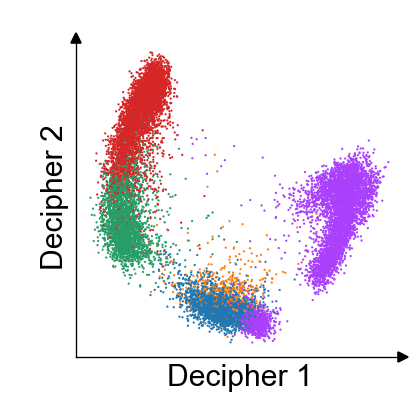

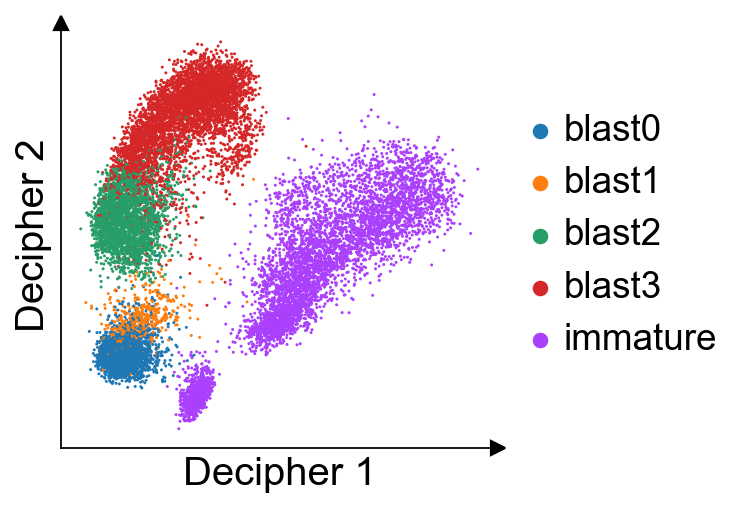

In [ ]:
decipher_config = dc.tl.DecipherConfig() # optional Decipher config

d1, val1 = dc.tl.decipher_train(
    adata, decipher_config, plot_kwargs={"color": "cell_type", "palette": color_palette}, plot_every_k_epochs=5,
)

### Rotate and flip the learned latent space to align it with the mechanisms of interest
We would ideally want `Decipher 1` to capture blast progression, and `Decipher 2` to discriminate `Healthy` and the AML sample.

2023-11-15 17:39:57,813 | INFO : Added `.obsm['decipher_v']`: the Decipher v space.
2023-11-15 17:39:57,813 | INFO : Added `.obsm['decipher_z']`: the Decipher z space.


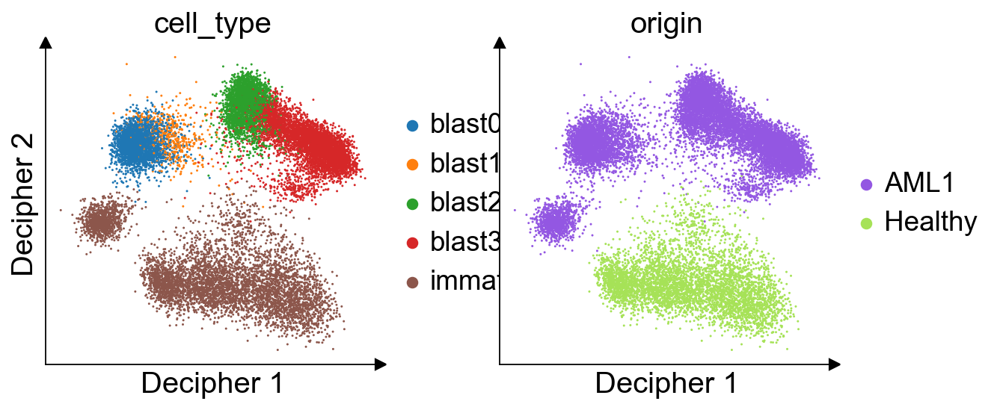

In [ ]:
dc.tl.decipher_rotate_space(
    adata,
    v1_col="cell_type",
    v1_order=["blast0", "blast1", "blast2", "blast3"],
    v2_col="origin",
    v2_order=["Healthy", "AML1"],
)
dc.pl.decipher(adata, ["cell_type", "origin"], palette=color_palette);

### We now cluster the cells using the `decipher_z` representation, and compute trajectories.

2023-11-15 17:39:58,766 | INFO : Clustering cells using scanpy Leiden algorithm.
2023-11-15 17:39:58,767 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2023-11-15 17:40:17,462 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
2023-11-15 17:40:21,457 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.


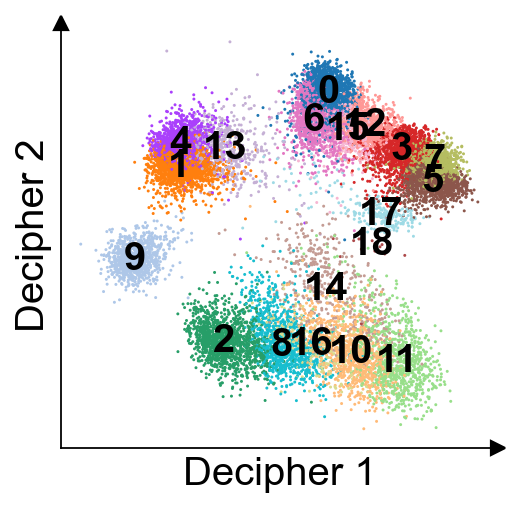

In [ ]:
dc.tl.cell_clusters(adata)
dc.pl.decipher(adata, ["decipher_clusters"], legend_loc="on data");

2023-11-15 17:40:21,887 | INFO : Trajectory Healthy : ['2', '8', '16', '10', '11'])
2023-11-15 17:40:21,891 | INFO : Added trajectory Healthy to `adata.uns['decipher']['trajectories']`.
2023-11-15 17:40:21,998 | INFO : Trajectory AML1 : ['9', '1', '4', '13', '6', '15', '12', '3', '7', '5'])
2023-11-15 17:40:22,005 | INFO : Added trajectory AML1 to `adata.uns['decipher']['trajectories']`.


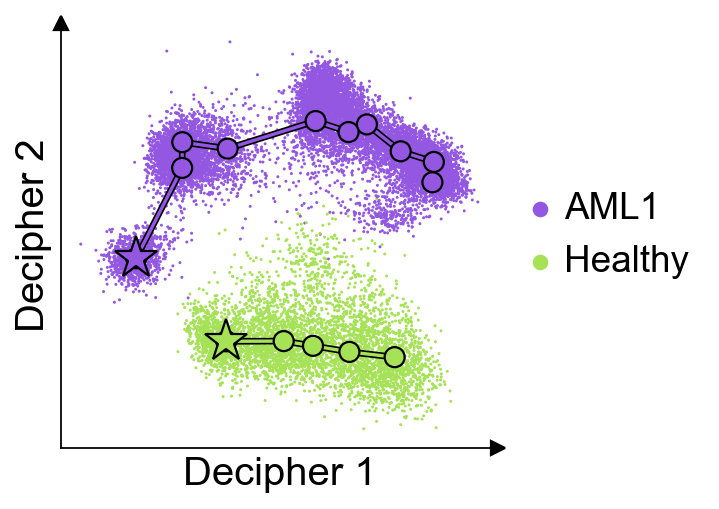

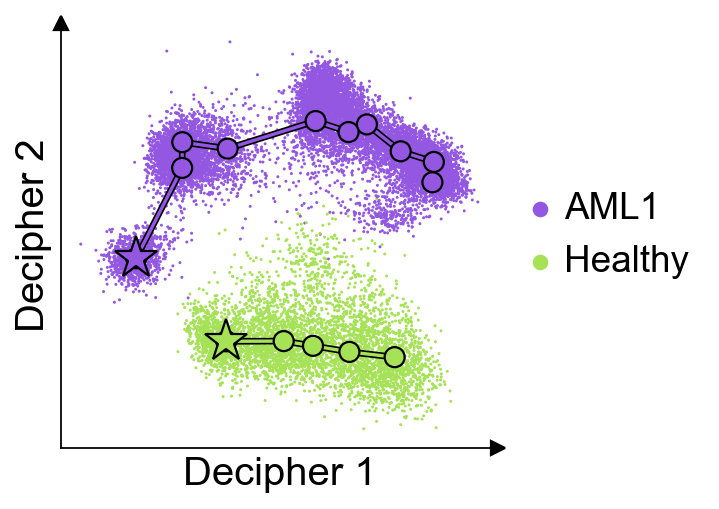

In [ ]:
dc.tl.trajectories(
    adata,
    dc.tl.TConfig("Healthy", "AVP", "MPO", "origin", "Healthy"),
    dc.tl.TConfig("AML1", "AVP", "CD68", "origin", "AML1"),
)
dc.pl.trajectories(adata, "origin", palette=color_palette)

2023-11-15 17:40:22,530 | INFO : Added `.obs['decipher_time']`: the decipher time of each cell.


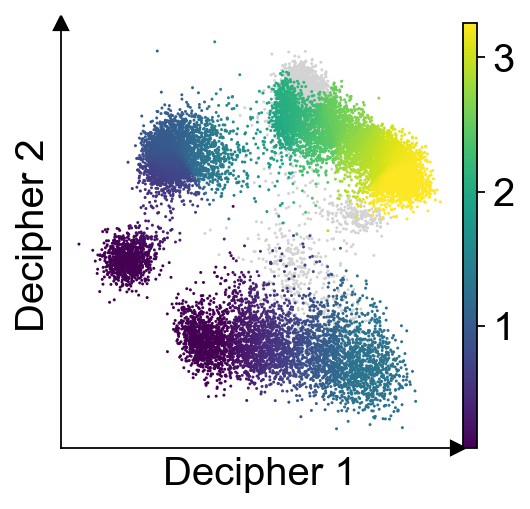

In [ ]:
dc.tl.decipher_time(adata)
dc.pl.decipher_time(adata);

### Compute gene patterns

In [ ]:
dc.tl.gene_patterns(adata)

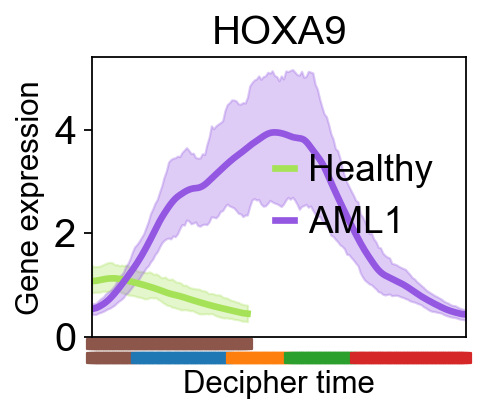

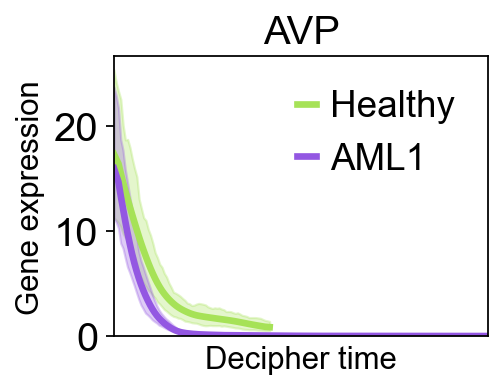

In [ ]:
dc.pl.gene_patterns(adata, "HOXA9", palette=color_palette, cell_type_key="cell_type")
dc.pl.gene_patterns(adata, "AVP", palette=color_palette);

### Compute basis decomposition

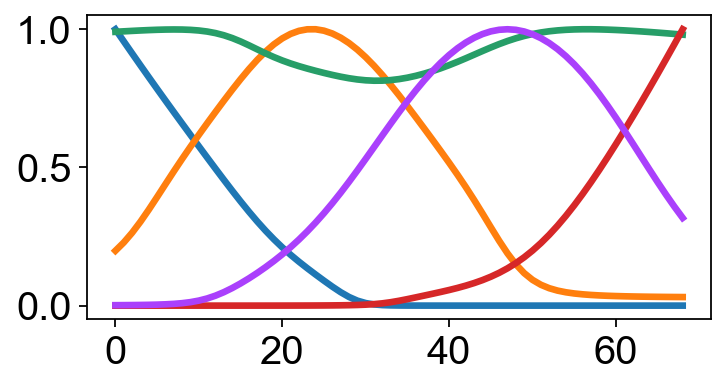

Loss: -966499.6 - Relative Error: 0.13%:  47%|███████████████████████████████████████████████▎                                                     | 4680/10000 [03:12<03:38, 24.31it/s]


In [ ]:
training_losses = dc.tl.basis_decomposition(adata, seed=0);

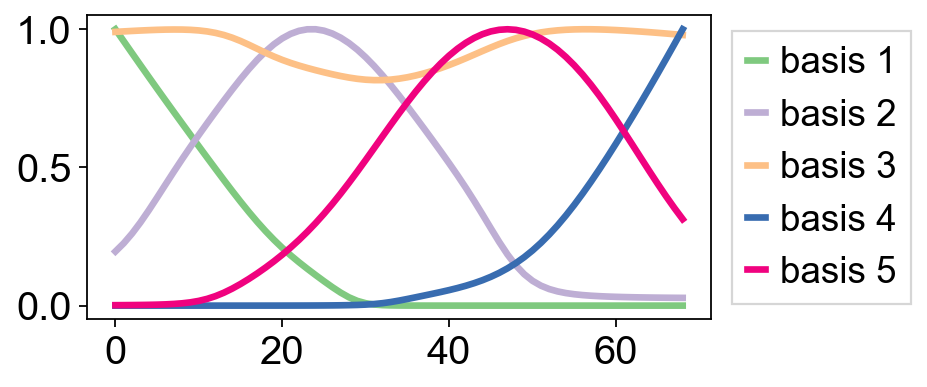

In [ ]:
colors = [sns.color_palette("Accent")[i] for i in [0, 1, 2, 4, 5]]
dc.pl.basis(adata, colors=colors);

In [ ]:
dc.tl.disruption_scores(adata)
adata.var[[c for c in adata.var if "decipher_disruption" in c]].sort_values(
    "decipher_disruption_combined", ascending=False
).head(10)

2023-11-15 17:43:38,551 | INFO : Added `.var['decipher_disruption_shape']`: shape disruption scores
2023-11-15 17:43:38,552 | INFO : Added `.var['decipher_disruption_scale']`: scale disruption scores
2023-11-15 17:43:38,552 | INFO : Added `.var['decipher_disruption_combined']`: combined disruption scores
2023-11-15 17:43:38,557 | INFO : Added `.uns['decipher']['disruption_scores']`: disruption scores
2023-11-15 17:43:38,558 | INFO : Added `.uns['decipher']['disruption_scores_samples']`: disruption scores probabilistic samples


,decipher_disruption_shape,decipher_disruption_scale,decipher_disruption_combined
index,,,
C1QTNF4,0.585618,2.450126,14.667301
DNTT,0.711000,5.786712,14.262213
CMTM8,0.341335,0.918616,12.359250
IGLL1,0.481286,2.751904,11.971736
UBE2C,0.674537,2.519647,11.882829
BIRC5,0.701430,2.449044,11.882485
RRM2,0.665228,2.000454,11.676637
MPO,0.132185,2.681761,11.662468
ICAM1,0.643572,3.076092,11.581854


## Other figures

In [ ]:
plt.rcParams["figure.figsize"] = [3,3]

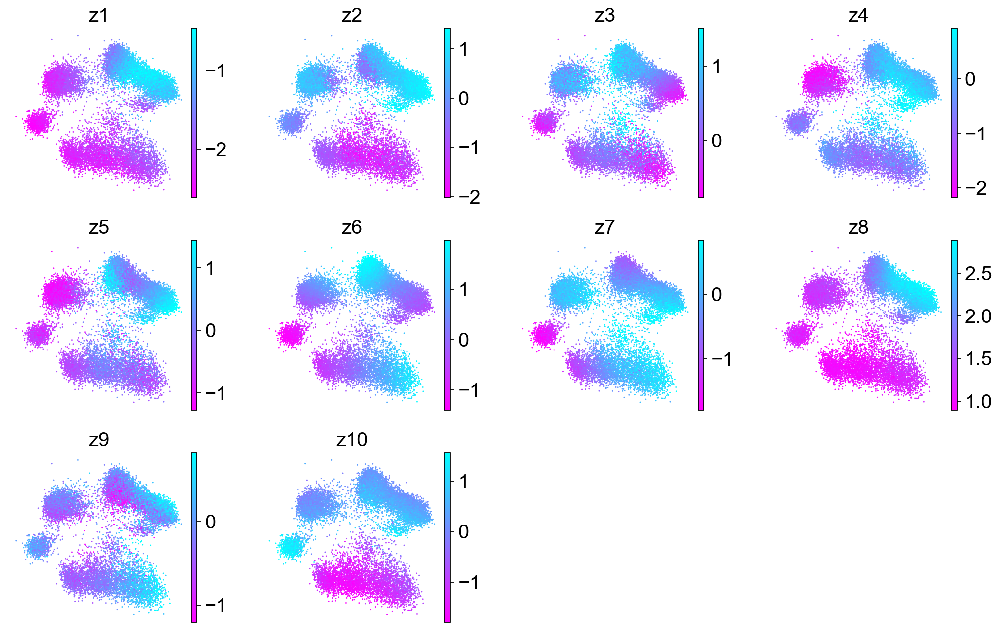

In [ ]:
dc.pl.decipher_z(adata);

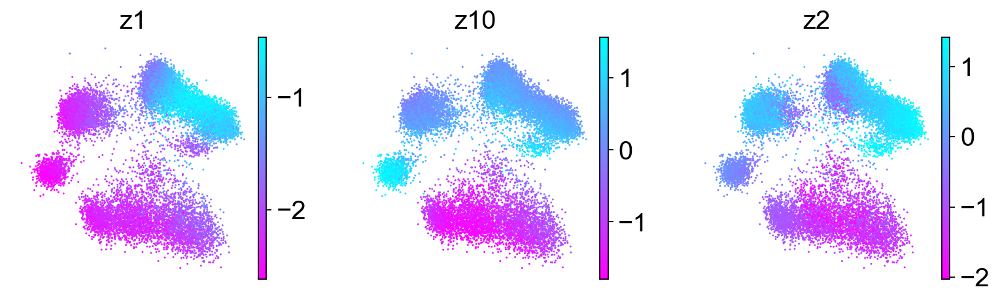

In [ ]:
fig = dc.pl.decipher_z(adata, subset_of_zs=[1,10,2]);

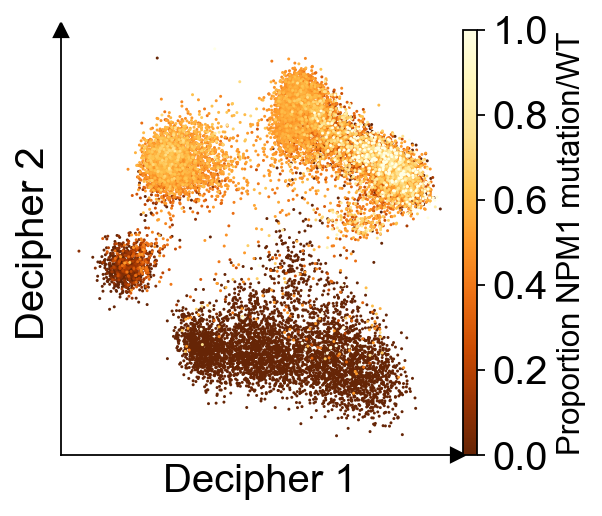

In [ ]:
fig = dc.pl.decipher(adata, "NPM1 mutation vs wild type", cmap=sns.color_palette("YlOrBr_r", as_cmap=True, ))
fig.axes[0].collections[-1].colorbar.set_label("Proportion NPM1 mutation/WT", fontsize=14)


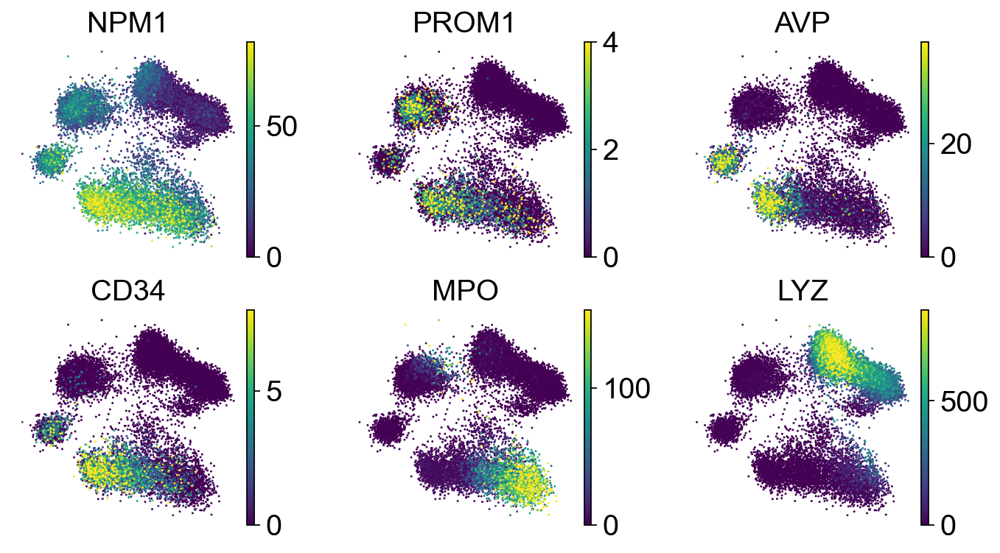

In [ ]:
dc.pl.decipher(
    adata,
    ["NPM1", "PROM1", "AVP", "CD34", "MPO", "LYZ"],
    ncols=3,
    vmax=lambda x: np.quantile(x, 0.99),
    figsize=(2.5, 2.5),
    axis_type=None
);